# Imports and load data

## Import libraries

In [130]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from cmcrameri import cm
import os
import socket
from roaring_landmask import RoaringLandmask

# ------------------------------------------------------------
# Load mean IWC profile data
# ------------------------------------------------------------


In [131]:
# Helper
def describe(arr):
    return {
        "count": arr.size,
        "mean": np.mean(arr),
        "std": np.std(arr),
        "min": np.min(arr),
        "5%": np.percentile(arr, 5),
        "25%": np.percentile(arr, 25),
        "50%": np.percentile(arr, 50),
        "75%": np.percentile(arr, 75),
        "95%": np.percentile(arr, 95),
        "max": np.max(arr),
    }


## Load data (Only bulk_data_df important)

In [132]:
if socket.gethostname()=='iacmac-ds4990':
    BULK_PATH = "/Volumes/University_stuff/Code_Projects/MSGI/Bulk_data/02"
else:
    BULK_PATH = "/nfs/ch4/wolke_scratch/dnikolo/GTE_Validation/DARDAR/Bulk_02/Bulk_statistics"
# bulk_data_df = pd.read_parquet(os.path.join(BULK_PATH,"glaciations_with_bulk_data_V3_1_2007.parquet"))
# iwc_rel_df_1 = pd.read_parquet(os.path.join(BULK_PATH,"iwc_rel_df_V3_1_2007.parquet"))
# iwc_rel_df_2 = pd.read_parquet(os.path.join(BULK_PATH,"iwc_rel_df_V3_1_2008.parquet"))
# mean_iwc_by_height_df = pd.read_parquet(os.path.join(BULK_PATH,"mean_iwc_by_height_data_V3_1_2007.parquet"))
# iwc_rel_df_loaded = pd.concat([iwc_rel_df_1, iwc_rel_df_2], ignore_index=True)

bulk_data_df_list=[]
for year in range(2006,2017):
    if year in [2011]:
        continue
    bulk_data_df_list.append(pd.read_parquet(os.path.join(BULK_PATH,f"glaciations_with_bulk_data_V3_1_{year}.parquet")))

bulk_data_df = pd.concat(bulk_data_df_list, ignore_index=True)

# bulk_data_df = pd.read_parquet(os.path.join(BULK_PATH,"glaciations_with_bulk_data_V3_1_2007.parquet"))
# bulk_data_debug = pd.read_parquet(os.path.join("/Volumes/University_stuff/Code_Projects/MSGI/Bulk_data/glaciations_with_bulk_data_V3_1_2007.parquet"))


Filter rows with no measurements (Cehck why are there such???)

In [133]:
bulk_data_df=bulk_data_df[bulk_data_df.apply(lambda row: not (len(row["bulk_height_means_m"])==0) , axis=1)]

## Split cells by pass

In [134]:
ROWS_1D=["ddc_cloud_top_temp_means_K","ddc_cloud_top_height_means_m", "iwc_top_means", "colocation_time"]

In [135]:
import numpy as np
import pandas as pd


def is_pass_list(x):
    """
    True if x looks like a per-pass list/array:
    e.g. [pass1, pass2] where each pass may itself be a list/array.
    """
    if isinstance(x, np.ndarray):
        return isinstance(x[0], np.ndarray)

    return False


def split_rows_by_pass(df, reference_col="bulk_height_means_m"):
    new_rows = []

    for _, row in df.iterrows():
        ref_val = row[reference_col]

        # Number of passes, e.g. len([[...], [...]]) == 2
        if is_pass_list(ref_val):
            n_passes = len(ref_val)
        else:
            n_passes = 1
        for pass_i in range(n_passes):
            new_row = {}

            for col in df.columns:
                val = row[col]
                # If this column contains per-pass values, take the matching pass
                if is_pass_list(val):
                    if pass_i < len(val):
                        new_row[col] = val[pass_i]
                    else:
                        # Leave empty if this column does not have this pass
                        new_row[col] = np.nan
                elif col in ROWS_1D:
                    new_row[col] = val[pass_i]
                else:
                    # Scalar / non-list values are copied to every split row
                    new_row[col] = val
                


            new_rows.append(new_row)

    return pd.DataFrame(new_rows, columns=df.columns)

# row = 

bulk_data_df_split = split_rows_by_pass(
    bulk_data_df,
    reference_col="bulk_height_means_m"
)
bulk_data_df_split = bulk_data_df_split[(bulk_data_df_split["avg_ctt"].isna()) | (((bulk_data_df_split["avg_ctt"]-273.15)<0) & ((bulk_data_df_split["avg_ctt"]-273.15)>-36))]
bulk_data_df_split


,Cloud_ID,Time [m],Magnitude,Glac_start_ind,Glac_peak_ind,Linear,line_rmse,Rate_arr,Mean_glac_rate,Glaciation time [h],...,bulk_height_means_m,ddc_cloud_top_height_means_m,ddc_cloud_top_temp_means_K,ext_bulk_means,temp_bulk_means,Z_bulk_means,cph_bulk_means,bulk_level_offset_top_m,bulk_level_offset_bottom_m,bulk_level_offset_mid_m
0,74447,240,0.510080,20,36,False,0.170899,"[0.06806687079627374, 0.08033324336606065, 0.0...",0.279615,4.00,...,"[6.943606, 6.6190763, 6.512773, 6.3652906, 6.2...",6.943606,243.479202,"[5.879125e-05, 7.710454e-05, 9.207271e-05, 0.0...","[243.4792, 245.65343, 246.38629, 247.45, 248.2...","[-24.436436, -21.817522, -20.682045, -19.17609...","[1.5473274, 1.6211456, 1.7641913, 1.9469033, 1...","[0.0, -120.0, -240.0, -360.0, -480.0, -600.0, ...","[-120.0, -240.0, -360.0, -480.0, -600.0, -720....","[-60.0, -180.0, -300.0, -420.0, -540.0, -660.0..."
1,98798,120,0.408134,7,15,True,0.090738,"[0.2040669023990631, 0.2040669023990631, 0.204...",0.204067,2.00,...,"[6.411936, 6.2900915, 6.172365, 6.0538216, 5.9...",6.411936,249.471664,"[0.00025640827, 0.0003735343, 0.00051449396, 0...","[249.47166, 250.43976, 251.37506, 252.26337, 2...","[-19.076298, -16.088455, -13.392471, -11.27006...","[1.738548, 1.7853035, 1.8524339, 1.9644789, 1....","[0.0, -120.0, -240.0, -360.0, -480.0, -600.0, ...","[-120.0, -240.0, -360.0, -480.0, -600.0, -720....","[-60.0, -180.0, -300.0, -420.0, -540.0, -660.0..."
2,112249,45,0.435897,0,3,True,0.106998,"[0.5811963081359863, 0.5811963081359863, 0.581...",0.581196,0.75,...,"[2.6627283, 2.5421157, 2.4083316, 2.315197, 2....",2.662728,249.336121,"[0.00028893206, 0.00045705857, 0.0006669469, 0...","[249.33612, 250.38997, 251.5435, 252.31972, 25...","[-25.101063, -22.422428, -19.418106, -18.18285...","[1.8400563, 1.8350871, 1.8396466, 1.863905, 1....","[0.0, -120.0, -240.0, -360.0, -480.0, -600.0, ...","[-120.0, -240.0, -360.0, -480.0, -600.0, -720....","[-60.0, -180.0, -300.0, -420.0, -540.0, -660.0..."
3,119993,240,0.926610,24,40,False,0.349386,"[0.02587255238800093, 0.17514474505330638, 0.1...",0.502297,4.00,...,"[6.5191355, 6.4039526, 6.281993, 6.159729, 6.0...",6.519135,244.658447,"[0.00022629875, 0.00035418788, 0.0005284226, 0...","[244.65845, 245.49803, 246.41396, 247.32436, 2...","[-18.805279, -15.516134, -13.029601, -10.80267...","[1.7855436, 1.8033655, 1.9213117, 1.9409319, 1...","[0.0, -120.0, -240.0, -360.0, -480.0, -600.0, ...","[-120.0, -240.0, -360.0, -480.0, -600.0, -720....","[-60.0, -180.0, -300.0, -420.0, -540.0, -660.0..."
4,149677,75,0.703200,16,21,True,0.079823,"[0.5625598430633545, 0.5625598430633545, 0.562...",0.562560,1.25,...,"[4.677273, 4.516191, 4.3961906, 4.2871428, 4.1...",4.677273,233.348282,"[0.00014071807, 0.00014838783, 0.00016950829, ...","[233.34828, 234.48384, 235.50519, 236.43951, 2...","[-30.412498, -30.407381, -28.737778, -25.71194...","[2.0, 2.0, 2.0, 1.984127, 1.9649123, 1.968254,...","[0.0, -120.0, -240.0, -360.0, -480.0, -600.0, ...","[-120.0, -240.0, -360.0, -480.0, -600.0, -720....","[-60.0, -180.0, -300.0, -420.0, -540.0, -660.0..."
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
16358,3123803,585,0.983371,21,60,False,0.338242,"[0.07739830425960673, 0.3077850129425298, 0.51...",0.315965,9.75,...,"[6.1847186, 5.967701, 5.85018, 5.630352, 5.579...",6.184719,231.336975,"[8.635258e-05, 6.2868065e-05, 5.5573186e-05, 4...","[231.33698, 233.16324, 234.20609, 235.77078, 2...","[nan, nan, nan, nan, nan, nan, nan, nan, nan, ...","[1.6240879, 1.5756347, 1.5814611, 1.5497338, 1...","[0.0, -120.0, -240.0, -360.0, -480.0, -600.0, ...","[-120.0, -240.0, -360.0, -480.0, -600.0, -720....","[-60.0, -180.0, -300.0, -420.0, -540.0, -660.0..."
16359,3124164,45,0.430545,0,3,False,0.117606,"[1.1372573286319834, 1.1372573286319834, 0.075...",0.783216,0.75,...,"[6.2764306, 6.148913, 6.016833, 5.909256, 5.79...",6.276431,231.394089,"[0.00032781676, 0.00024174793, 0.00022174507, ...","[231.39409, 232.19856, 233.20273, 234.06366, 2..."

In [136]:
bulk_data_df_split.keys()

Index(['Cloud_ID', 'Time [m]', 'Magnitude', 'Glac_start_ind', 'Glac_peak_ind',
       'Linear', 'line_rmse', 'Rate_arr', 'Mean_glac_rate',
       'Glaciation time [h]', 'tracknumber', 'is_large_pix_cloud',
       'is_cot_valid_cloud', 'is_ctp_valid_cloud', 'is_liq', 'is_mix',
       'is_ice', 'max_water_frac', 'max_ice_fraction', 'avg_size[km]',
       'max_size[km]', 'min_size[km]', 'avg_size[px]', 'max_size[px]',
       'min_size[px]', 'track_start_time', 'track_length', 'avg_cot',
       'avg_ctp', 'avg_ctt', 'glaciation_start_time', 'glaciation_end_time',
       'avg_lat', 'avg_lon', 'start_ice_fraction', 'end_ice_fraction',
       'ice_frac_hist', 'cot_hist', 'cot_std_hist', 'cot_nan_frac_hist',
       'ctp_hist', 'ctp_std_hist', 'ctp_nan_frac_hist', 'ctt_hist',
       'ctt_std_hist', 'lat_hist', 'lon_hist', 'size_hist_km',
       'size_hist_km_debug', 'val_ice_frac_hist', 'val_ice_frac_std_hist',
       'val_ice_frac_dev_hist', 'val_pix_claas_if_hist',
       'val_pix_claas_if_st

In [8]:
np.nanmax(np.concat(bulk_data_df_split["iwc_bulk_means"].to_numpy()))

np.float32(-25.417582)

In [9]:
((bulk_data_df_split["avg_ctt"].isna()) | (((bulk_data_df_split["avg_ctt"]-273.15)<0) & (bulk_data_df_split["avg_ctt"]-273.15)>-36)).value_counts()

avg_ctt
True    16035
Name: count, dtype: int64

In [138]:
test_row=bulk_data_df_split.iloc[0]

## Stats by relative time

In [139]:
ORIGINAL_VALID_CLOUD_COLUMNS = bulk_data_df.columns.tolist()

bulk_data_df_split["rel_ind"] = bulk_data_df_split.apply(
    lambda row: int(round(
        (pd.Timestamp(row["colocation_time"]) - row["track_start_time"]) / pd.Timedelta(minutes=15)
    )) - int(row["Glac_peak_ind"]),
    axis=1
)
bulk_data_df_split["rel_time_min"] = bulk_data_df_split["rel_ind"]*15
sample = bulk_data_df_split.sample(100, random_state=1)

In [140]:
def generate_stats_by_rel_time(df, mode="mean"):
    if mode == "mean":
        stats_by_rel_time = (
            df
            .groupby("rel_ind")
            .agg(
                n_hits=("iwc_bulk_means", "count"),

                mean_iwc_profile=(
                    "iwc_bulk_means",
                    lambda profiles: np.nanmean(np.stack(profiles), axis=0),
                ),
                mean_Z_profile=(
                    "Z_bulk_means",
                    lambda profiles: np.nanmean(np.stack(profiles), axis=0),
                ),
                mean_ext_profile=(
                    "ext_bulk_means",
                    lambda profiles: np.nanmean(np.stack(profiles), axis=0),
                ),
                mean_temp_profile=(
                    "temp_bulk_means",
                    lambda profiles: np.nanmean(np.stack(profiles), axis=0),
                ),

                mean_bulk_height_profile_m=(
                    "bulk_level_offset_mid_m",
                    lambda profiles: np.nanmean(np.stack(profiles), axis=0),
                ),

                bulk_offset_top_m=(
                    "bulk_level_offset_top_m",
                    lambda profiles: np.nanmean(np.stack(profiles), axis=0),
                ),

                bulk_offset_bottom_m=(
                    "bulk_level_offset_bottom_m",
                    lambda profiles: np.nanmean(np.stack(profiles), axis=0),
                ),

                dd_cth=(
                    "ddc_cloud_top_height_means_m",
                    "mean",
                ),

                sev_cth=(
                    "avg_cth",
                    "mean",
                ),

                dd_ctt=(
                    "ddc_cloud_top_temp_means_K",
                    "mean",
                ),

                mean_iwc_ct=(
                    "iwc_top_means",
                    "mean",
                ),

                sev_ctt=(
                    "avg_ctt",
                    "mean",
                ),
                
                mean_area_km=(
                    "avg_size[km]",
                    "mean",
                ),
                
            )
            .reset_index()
        )
    elif mode=="median":
        print("Calculating median")
        stats_by_rel_time = (
        df
        .groupby("rel_ind")
        .agg(
            n_hits=("iwc_bulk_means", "count"),

            mean_iwc_profile=(
                "iwc_bulk_means",
                lambda profiles: np.nanmedian(np.stack(profiles), axis=0),
            ),
            mean_Z_profile=(
                "Z_bulk_means",
                lambda profiles: np.nanmedian(np.stack(profiles), axis=0),
            ),
            mean_ext_profile=(
                "ext_bulk_means",
                lambda profiles: np.nanmedian(np.stack(profiles), axis=0),
            ),
            mean_temp_profile=(
                "temp_bulk_means",
                lambda profiles: np.nanmedian(np.stack(profiles), axis=0),
            ),

            mean_bulk_height_profile_m=(
                "bulk_level_offset_mid_m",
                lambda profiles: np.nanmedian(np.stack(profiles), axis=0),
            ),

            bulk_offset_top_m=(
                "bulk_level_offset_top_m",
                lambda profiles: np.nanmedian(np.stack(profiles), axis=0),
            ),

            bulk_offset_bottom_m=(
                "bulk_level_offset_bottom_m",
                lambda profiles: np.nanmedian(np.stack(profiles), axis=0),
            ),

            dd_cth=(
                "ddc_cloud_top_height_means_m",
                "median",
            ),

            sev_cth=(
                "avg_cth",
                "median",
            ),

            dd_ctt=(
                "ddc_cloud_top_temp_means_K",
                "median",
            ),

            mean_iwc_ct=(
                "iwc_top_means",
                "median",
            ),


            sev_ctt=(
                "avg_ctt",
                "median",
            ),
            
            mean_area_km=(
                "avg_size[km]",
                "median",
            ),
            
            )
            .reset_index()
        )
    else:
        raise ValueError("Set statistics 'MODE' to mean or median")
    stats_by_rel_time["rel_time_min"] = stats_by_rel_time["rel_ind"] * 15
    return stats_by_rel_time

# Settings

In [141]:
# Working version. IMPORTANT. DON'T DELETE!!!
l2_start = 4
l_depth=8
n_agg_levels=3

# l2_start = 4
# l_depth=7
# n_agg_levels=4

n_total_levels = l2_start+l_depth*(n_agg_levels-1)
if n_total_levels>25:
    raise ValueError(f"No more than 30 total levels now {n_total_levels}")
iqr_filter_y=True
iqr_filter_x=True
ind_range = [-3, 4]


rel_times_min = np.array(np.arange(ind_range[0],ind_range[1])*15,dtype=int)
timesteps = [i for i in range(2, -3, -1)]
mean_mode = "log"
confidence_level = 0.9  # 0.68, 0.90, 0.95, 0.99, etc.
n_bootstrap = 5000
ALLOWED_CTH_DEV=1000
eps=1e-5


In [142]:
# ------------------------------------------------------------------
# 0. Configuration
# ------------------------------------------------------------------
PEAK_IND = 0
# Absolute index (same numbering as `inds`) of the column where
# rel_ind == 0. Must be set. E.g. PEAK_IND = ind_range[0] + 8

WEIGHT_MODE = "none"
# "residual" : w = 1 - rho**2   -> variance not shared with the peak
# "abs"      : w = 1 - |rho|
# "signed"   : w = 1 - max(rho, 0)   (ignores anticorrelation)
# "none"     : w = 1                 (reproduces your current result)

WEIGHT_FLOOR = 0.00
# Minimum weight. rho == 1 at the peak would otherwise delete that
# column from every reference sample. Set to 0.0 to allow that.

INVERT_WEIGHTS = False
# True -> emphasise peak-correlated times instead of down-weighting
# them (w = rho**2 etc.). Use if you want the reference to be "the
# same storms", not "independent background".

EQUALISE_INDEX_SIZE = False
# True -> additionally divide by the per-index cloud count, so each
# time index contributes equally regardless of how many clouds it has
# (n_clouds in your table ranges 46k-348k).

# Prepare data

## Optical properties

In [192]:
# def calculate_top_depth(row):
#     tot_thickness = 0
#     small_ext_counter = 0
#     for j, ext in enumerate(row["ext_bulk_means"]):
#         lev_depth = row.bulk_level_offset_top_m[j]-row.bulk_level_offset_bottom_m[j]
#         tot_thickness += lev_depth*ext
#         if ext<2.0e-4:
#             small_ext_counter+=1
#         if tot_thickness>=0.2:
#             # print(tot_thickness,j*120,small_ext_counter*120)
#             return j*120
#     return None
        
            
# sample["ct_depth"] = sample.apply(calculate_top_depth,axis=1)

In [193]:
# (sample["ct_depth"]>600).value_counts()

In [194]:
def optical_depth_path(row):
    if row.bulk_level_offset_top_m is None:
        return None

    z_top = np.asarray(row.bulk_level_offset_top_m, dtype=float)
    z_bottom = np.asarray(row.bulk_level_offset_bottom_m, dtype=float)
    ext = np.asarray(row["ext_bulk_means"], dtype=float)

    dz = np.abs(z_top - z_bottom)

    # optional safety check
    if len(dz) != len(ext):
        raise ValueError(
            f"Length mismatch: dz has {len(dz)} layers, extinction has {len(ext)} values"
        )

    tau_path = [0.0]
    depth_path = [0.0]

    tau = 0.0
    depth = 0.0

    for layer_dz, layer_ext in zip(dz, ext):
        layer_tau = layer_dz * layer_ext

        tau += layer_tau
        depth += layer_dz

        tau_path.append(tau)
        depth_path.append(depth)

    return {
        "depth_m": np.asarray(depth_path),
        "tau": np.asarray(tau_path)
    }

def calculate_ct_depth(row, cod_threshold=0.2):
    tau = optical_depth_path(row)["tau"]
    top_idx = np.argmax(tau>cod_threshold)
    if top_idx==0 and tau[-1]<cod_threshold:
        return np.nan
    return top_idx*120

In [959]:
n_total_levels

20

In [960]:
# Calculate total optical depth per cloud 
bulk_data_df_split["3km_cot"] = bulk_data_df_split.apply(lambda row: optical_depth_path(row)["tau"][-1], axis=1)
bulk_data_df_split["continious_cloud"] = bulk_data_df_split.apply(lambda row: (((optical_depth_path(row)["tau"][1:]-optical_depth_path(row)["tau"][:-1])/0.120)>0.1)[:20].all(), axis=1)
# bulk_data_df_split["continious_cloud"] = bulk_data_df_split.apply(lambda row: ((optical_depth_path(row)["tau"][1:]-optical_depth_path(row)["tau"][:-1])>5*1e-4)[:7].all(), axis=1)
bulk_data_df_split["ct_depth"]=bulk_data_df_split.apply(calculate_ct_depth,axis=1)

In [196]:
(bulk_data_df_split["ct_depth"].isna()).value_counts()

ct_depth
False    12996
True      3039
Name: count, dtype: int64

In [197]:
(bulk_data_df_split["3km_cot"]<0.2).value_counts()

3km_cot
False    12996
True      3039
Name: count, dtype: int64

In [198]:
bulk_data_df_split["ct_depth"].isna().value_counts()

ct_depth
False    12996
True      3039
Name: count, dtype: int64

In [199]:
bulk_data_df_split["ct_depth"].isna().value_counts()

ct_depth
False    12996
True      3039
Name: count, dtype: int64

In [200]:
bulk_data_df_split.iloc[0]["val_cth_hist"]

array([-1.00000000e+00, -1.00000000e+00, -1.00000000e+00, -1.00000000e+00,
       -1.00000000e+00, -1.00000000e+00, -1.00000000e+00, -1.00000000e+00,
       -1.00000000e+00, -1.00000000e+00, -1.00000000e+00, -1.00000000e+00,
       -1.00000000e+00, -1.00000000e+00, -1.00000000e+00, -1.00000000e+00,
       -1.00000000e+00, -1.00000000e+00, -1.00000000e+00, -1.00000000e+00,
       -1.00000000e+00, -1.00000000e+00, -1.00000000e+00, -1.00000000e+00,
       -1.00000000e+00, -1.00000000e+00, -1.00000000e+00, -1.00000000e+00,
       -1.00000000e+00, -1.00000000e+00, -1.00000000e+00, -1.00000000e+00,
       -1.00000000e+00, -1.00000000e+00, -1.00000000e+00, -1.00000000e+00,
       -1.00000000e+00, -1.00000000e+00, -1.00000000e+00, -1.00000000e+00,
       -1.00000000e+00, -1.00000000e+00, -1.00000000e+00, -1.00000000e+00,
       -1.00000000e+00, -1.00000000e+00, -1.00000000e+00, -1.00000000e+00,
       -1.00000000e+00, -1.00000000e+00, -1.00000000e+00, -1.00000000e+00,
       -1.00000000e+00, -

## Check coincidence

In [201]:
bulk_data_df_split.iloc[1]["val_pix_claas_cth_hist"] 

array([-1.00000000e+00, -1.00000000e+00, -1.00000000e+00,  6.12986768e+03,
       -1.00000000e+00, -1.00000000e+00, -1.00000000e+00, -1.00000000e+00,
       -1.00000000e+00, -1.00000000e+00, -1.00000000e+00, -1.00000000e+00,
       -1.00000000e+00, -1.00000000e+00, -1.00000000e+00, -1.00000000e+00,
       -1.00000000e+00, -1.00000000e+00, -1.00000000e+00, -1.00000000e+00,
       -1.00000000e+00, -1.00000000e+00, -1.00000000e+00, -1.00000000e+00,
       -1.00000000e+00, -1.00000000e+00, -1.00000000e+00, -1.00000000e+00,
       -1.00000000e+00, -1.00000000e+00, -1.00000000e+00, -1.00000000e+00,
       -1.00000000e+00, -1.00000000e+00, -1.00000000e+00, -1.00000000e+00,
       -1.00000000e+00, -1.00000000e+00, -1.00000000e+00, -1.00000000e+00,
       -1.00000000e+00, -1.00000000e+00, -1.00000000e+00, -1.00000000e+00,
       -1.00000000e+00, -1.00000000e+00, -1.00000000e+00, -1.00000000e+00,
       -1.00000000e+00, -1.00000000e+00, -1.00000000e+00, -1.00000000e+00,
       -1.00000000e+00, -

In [202]:
np.isnan(bulk_data_df_split.iloc[0]["ct_depth"])

True

In [203]:
def _check_val_seviri_coincidence(row):
    points_of_interest = row["val_cth_hist"] > 0
    target_ind = int((row["colocation_time"]-row["track_start_time"])/pd.Timedelta(minutes=15))
    if not points_of_interest[target_ind]:
        print("weird")
        return False
    if type(row["cth_hist"]) == float:
        print("weird")
        return False
    if np.isnan(row["ct_depth"]) or row["val_pix_claas_cth_hist"][target_ind]<=0:
        return False
    cth_deviation = np.abs(row["val_pix_claas_cth_hist"][target_ind] + row["ct_depth"] - row["val_cth_hist"][target_ind])
    # cth_deviations = np.abs(row["cth_hist"][target_ind] - row["ct_depth"] - row["val_cth_hist"][target_ind])
    # if cth_deviations.size == 0:
    #     return False
    # mean_height_dev = cth_deviations.mean()  
    # if mean_height_dev > ALLOWED_CTH_DEV:
    #     return False
    if cth_deviation > ALLOWED_CTH_DEV or np.isnan(cth_deviation):
        # print(cth_deviation)
        return False
    return True

def _calculate_cth_deviation(row):
    points_of_interest = row["val_cth_hist"] > 0
    target_ind = int((row["colocation_time"]-row["track_start_time"])/pd.Timedelta(minutes=15))
    if not points_of_interest[target_ind]:
        print("weird")
        return np.nan
    if type(row["cth_hist"]) == float:
        print("weird")
        return np.nan
    if np.isnan(row["ct_depth"]) or row["val_pix_claas_cth_hist"][target_ind]<=0:
        return np.nan
    cth_deviation = row["val_pix_claas_cth_hist"][target_ind] + row["ct_depth"] - row["val_cth_hist"][target_ind]
    # cth_deviations = np.abs(row["cth_hist"][target_ind] - row["ct_depth"] - row["val_cth_hist"][target_ind])
    # if cth_deviations.size == 0:
    #     return False
    # mean_height_dev = cth_deviations.mean()  
    # if mean_height_dev > ALLOWED_CTH_DEV:
    #     return False
    return cth_deviation


In [204]:
bulk_data_df_split["cth_deviation"] = bulk_data_df_split.apply(_calculate_cth_deviation,axis=1)

(array([  13.,   24.,   49.,   78.,  183.,  345.,  688., 1512., 2885.,
        2458., 1275.,  576.,  277.,  116.,   51.,   14.]),
 array([-4000., -3500., -3000., -2500., -2000., -1500., -1000.,  -500.,
            0.,   500.,  1000.,  1500.,  2000.,  2500.,  3000.,  3500.,
         4000.]),
 <BarContainer object of 16 artists>)

findfont: Font family 'arial' not found.
findfont: Font family 'arial' not found.
findfont: Font family 'arial' not found.
findfont: Font family 'arial' not found.
findfont: Font family 'arial' not found.
findfont: Font family 'arial' not found.
findfont: Font family 'arial' not found.
findfont: Font family 'arial' not found.
findfont: Font family 'arial' not found.
findfont: Font family 'arial' not found.
findfont: Font family 'arial' not found.
findfont: Font family 'arial' not found.
findfont: Font family 'arial' not found.
findfont: Font family 'arial' not found.
findfont: Font family 'arial' not found.
findfont: Font family 'arial' not found.
findfont: Font family 'arial' not found.
findfont: Font family 'arial' not found.
findfont: Font family 'arial' not found.
findfont: Font family 'arial' not found.
findfont: Font family 'arial' not found.
findfont: Font family 'arial' not found.
findfont: Font family 'arial' not found.
findfont: Font family 'arial' not found.
findfont: Font f

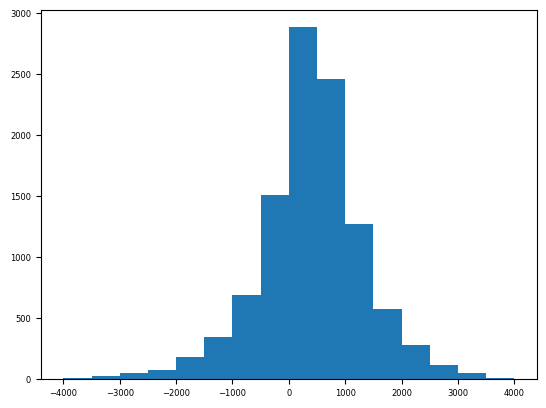

In [205]:
plt.hist(bulk_data_df_split["cth_deviation"],bins=np.arange(-4000,4001,500))

In [206]:
sample_cloud = bulk_data_df_split.iloc[3]
sample_cloud.val_pix_claas_cth_hist

array([-1.00000000e+00, -1.00000000e+00, -1.00000000e+00, -1.00000000e+00,
       -1.00000000e+00, -1.00000000e+00, -1.00000000e+00, -1.00000000e+00,
       -1.00000000e+00, -1.00000000e+00, -1.00000000e+00, -1.00000000e+00,
       -1.00000000e+00, -1.00000000e+00, -1.00000000e+00, -1.00000000e+00,
       -1.00000000e+00, -1.00000000e+00, -1.00000000e+00, -1.00000000e+00,
       -1.00000000e+00, -1.00000000e+00, -1.00000000e+00, -1.00000000e+00,
       -1.00000000e+00, -1.00000000e+00, -1.00000000e+00, -1.00000000e+00,
       -1.00000000e+00, -1.00000000e+00, -1.00000000e+00,  5.72094971e+03,
       -1.00000000e+00, -1.00000000e+00, -1.00000000e+00, -1.00000000e+00,
       -1.00000000e+00, -1.00000000e+00, -1.00000000e+00, -1.00000000e+00,
       -1.00000000e+00, -1.00000000e+00])

In [207]:
sample_cloud.cth_deviation

-339.30800333744355

In [208]:
sample_cloud.keys()

Index(['Cloud_ID', 'Time [m]', 'Magnitude', 'Glac_start_ind', 'Glac_peak_ind',
       'Linear', 'line_rmse', 'Rate_arr', 'Mean_glac_rate',
       'Glaciation time [h]',
       ...
       'rel_ind', 'rel_time_min', '3km_cot', 'continious_cloud', 'ct_depth',
       'cth_deviation', 'surface_type', 'is_maritime', 'n_meas', 'val_ctt'],
      dtype='object', length=102)

In [209]:
bulk_data_df_split["cth_deviation"]

0                NaN
1         164.055372
2                NaN
3        -339.308003
4        -136.909100
            ...     
16358    1845.453596
16359    -369.050179
16360            NaN
16361    1385.698314
16362    -125.461531
Name: cth_deviation, Length: 16035, dtype: float64

In [210]:
bulk_data_df_split["val_seviri_coincidence"] = bulk_data_df_split.apply(_check_val_seviri_coincidence,axis=1)

In [211]:
bulk_data_df_split["val_seviri_coincidence"].value_counts()

val_seviri_coincidence
False    8492
True     7543
Name: count, dtype: int64

In [212]:
# print(np.argmax(optical_depth_path(bulk_data_filtered.iloc[0])["tau"]>0.3))
# print(optical_depth_path(bulk_data_filtered.iloc[0])["tau"])

<Figure size 700x500 with 0 Axes>

findfont: Font family 'arial' not found.
findfont: Font family 'arial' not found.
findfont: Font family 'arial' not found.
findfont: Font family 'arial' not found.
findfont: Font family 'arial' not found.
findfont: Font family 'arial' not found.
findfont: Font family 'arial' not found.
findfont: Font family 'arial' not found.
findfont: Font family 'arial' not found.
findfont: Font family 'arial' not found.
findfont: Font family 'arial' not found.
findfont: Font family 'arial' not found.
findfont: Font family 'arial' not found.
findfont: Font family 'arial' not found.
findfont: Font family 'arial' not found.
findfont: Font family 'arial' not found.
findfont: Font family 'arial' not found.
findfont: Font family 'arial' not found.
findfont: Font family 'arial' not found.
findfont: Font family 'arial' not found.
findfont: Font family 'arial' not found.
findfont: Font family 'arial' not found.
findfont: Font family 'arial' not found.
findfont: Font family 'arial' not found.
findfont: Font f

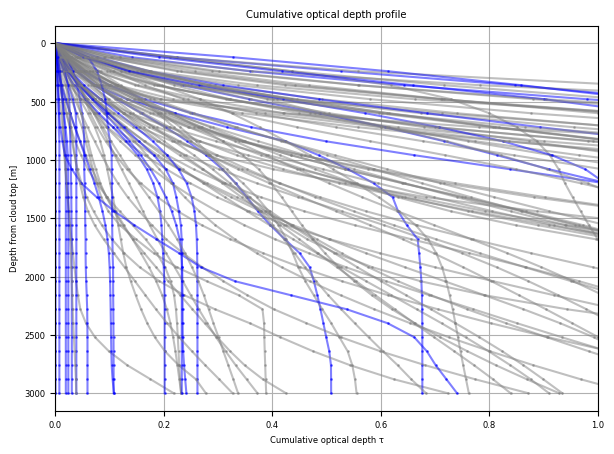

In [213]:
import numpy as np
import matplotlib.pyplot as plt

import numpy as np
import matplotlib.pyplot as plt




plt.figure(figsize=(7, 5))

plt.figure(figsize=(7, 5))

for row_idx, row in sample.iterrows():
    p = optical_depth_path(row)

    if p is None:
        continue
    if ((p["tau"][1:]-p["tau"][:-1])<5*1e-4).any():
        plt.plot(
            p["tau"],
            p["depth_m"],
            alpha=0.5,
            marker="o",
            color="blue",
            markersize=1
        )
    else:
        plt.plot(
            p["tau"],
            p["depth_m"],
            alpha=0.5,
            marker="o",
            color="gray",
            markersize=1
        )



# plt.axvline(0.2, linestyle="--", linewidth=1, label="τ = 0.2")

plt.xlabel("Cumulative optical depth τ")
plt.ylabel("Depth from cloud top [m]")
plt.title("Cumulative optical depth profile")
plt.grid(True)
plt.xlim(0, 1)

# Optional: depth increasing downward
plt.gca().invert_yaxis()

plt.show()

findfont: Font family 'arial' not found.
findfont: Font family 'arial' not found.
findfont: Font family 'arial' not found.
findfont: Font family 'arial' not found.
findfont: Font family 'arial' not found.
findfont: Font family 'arial' not found.
findfont: Font family 'arial' not found.
findfont: Font family 'arial' not found.
findfont: Font family 'arial' not found.
findfont: Font family 'arial' not found.
findfont: Font family 'arial' not found.
findfont: Font family 'arial' not found.
findfont: Font family 'arial' not found.
findfont: Font family 'arial' not found.
findfont: Font family 'arial' not found.
findfont: Font family 'arial' not found.
findfont: Font family 'arial' not found.
findfont: Font family 'arial' not found.
findfont: Font family 'arial' not found.
findfont: Font family 'arial' not found.
findfont: Font family 'arial' not found.
findfont: Font family 'arial' not found.
findfont: Font family 'arial' not found.
findfont: Font family 'arial' not found.
findfont: Font f

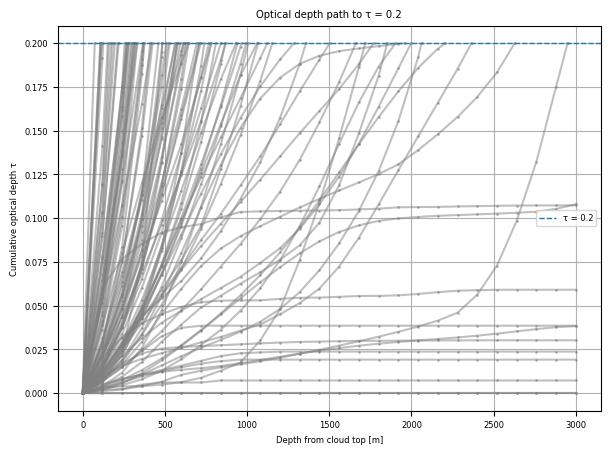

In [214]:
import numpy as np
import matplotlib.pyplot as plt
import numpy as np
import matplotlib.pyplot as plt

def optical_depth_path_to_03(row, tau_target=0.2):
    if row.bulk_level_offset_top_m is None:
        return None

    z_top = np.asarray(row.bulk_level_offset_top_m, dtype=float)
    z_bottom = np.asarray(row.bulk_level_offset_bottom_m, dtype=float)
    ext_profile = np.asarray(row["ext_bulk_means"], dtype=float)

    dz = np.abs(z_top - z_bottom)

    if len(dz) != len(ext_profile):
        raise ValueError(
            f"Length mismatch: dz has {len(dz)} layers, "
            f"extinction has {len(ext_profile)} values"
        )

    tau = 0.0
    depth = 0.0

    depth_path = [0.0]
    tau_path = [0.0]

    for layer_dz, ext in zip(dz, ext_profile):
        layer_tau = layer_dz * ext

        # if tau_target is reached inside this layer, interpolate
        if tau + layer_tau >= tau_target:
            remaining_tau = tau_target - tau

            if ext > 0:
                depth_inside_layer = remaining_tau / ext
            else:
                depth_inside_layer = layer_dz

            depth += depth_inside_layer
            tau = tau_target

            depth_path.append(depth)
            tau_path.append(tau)
            break

        tau += layer_tau
        depth += layer_dz

        depth_path.append(depth)
        tau_path.append(tau)

    return {
        "depth_m": np.asarray(depth_path),
        "tau": np.asarray(tau_path),
        "reached_03": tau >= tau_target
    }

plt.figure(figsize=(7, 5))

for row_idx, row in sample.iterrows():
    p = optical_depth_path_to_03(row, tau_target=0.2)

    if p is None:
        continue

    plt.plot(
        p["depth_m"],
        p["tau"],
        alpha=0.5,
        marker="o",
        color="gray",
        markersize=1
    )

plt.axhline(0.2, linestyle="--", linewidth=1, label="τ = 0.2")

plt.xlabel("Depth from cloud top [m]")
plt.ylabel("Cumulative optical depth τ")
plt.title("Optical depth path to τ = 0.2")
plt.grid(True)
plt.legend()
plt.show()

## Filter Data

In [215]:
landmask = RoaringLandmask.new()
def classify_surface(lats, lons):
    """
    lats, lons: arrays in degrees
    returns: array of 'maritime' or 'land'
    """
    is_land = np.array([
        landmask.contains(lon, lat)
        for lat, lon in zip(lats, lons)
    ])

    return np.where(is_land, "land", "maritime")


bulk_data_df_split["surface_type"] = bulk_data_df_split.apply(lambda row: classify_surface(
    row["lat_hist"],
    row["lon_hist"]
),axis=1)
bulk_data_df_split["is_maritime"] = bulk_data_df_split.apply(lambda row: (row["surface_type"]=="maritime").mean()>=1, axis=1)

In [216]:
bulk_data_df_split["n_meas"] = bulk_data_df_split.apply(lambda row: len(row["ice_frac_hist"]),axis=1)
bulk_data_df_split["val_ctt"] = bulk_data_df_split.apply(lambda row: row['temp_bulk_means'][0],axis=1)

In [217]:
bulk_data_df_split["temp_bulk_means"]

0        [243.4792, 245.65343, 246.38629, 247.45, 248.2...
1        [249.47166, 250.43976, 251.37506, 252.26337, 2...
2        [249.33612, 250.38997, 251.5435, 252.31972, 25...
3        [244.65845, 245.49803, 246.41396, 247.32436, 2...
4        [233.34828, 234.48384, 235.50519, 236.43951, 2...
                               ...                        
16358    [231.33698, 233.16324, 234.20609, 235.77078, 2...
16359    [231.39409, 232.19856, 233.20273, 234.06366, 2...
16360    [254.28687, 255.13057, 255.9903, 256.63965, na...
16361    [244.91705, 245.73486, 246.6574, 247.5189, 248...
16362    [232.74506, 233.9592, 235.23427, 236.83446, 23...
Name: temp_bulk_means, Length: 16035, dtype: object

In [241]:
# Filter only for clouds that survive after glaciation
bulk_data_colocated = bulk_data_df_split[bulk_data_df_split["val_seviri_coincidence"]]
# bulk_data_filtered = bulk_data_colocated[bulk_data_colocated.track_length / pd.Timedelta(minutes=15) > bulk_data_colocated["Glac_peak_ind"]]
bulk_data_filtered = bulk_data_colocated[(bulk_data_colocated["n_meas"]-1) > bulk_data_colocated["Glac_peak_ind"]]
# Filter for cloud lifetime - not too long
# bulk_data_filtered = bulk_data_filtered[bulk_data_filtered.track_length < pd.Timedelta(hours=12)]

# Filter for significant bulk optical thickness
# bulk_data_filtered = bulk_data_filtered[bulk_data_filtered["3km_cot"]>0.6]
# Select only one pass where 2 are available
bulk_data_filtered = bulk_data_filtered.drop_duplicates(subset="Cloud_ID", keep="first")
# Filter for cclouds where extinction doesn't drop in the 2 kilometers
bulk_data_filtered = bulk_data_filtered[bulk_data_filtered["continious_cloud"]]
# Filter for cloud type
# bulk_data_filtered= bulk_data_filtered[bulk_data_filtered["Cloud type"].isin(["Altostratus", "Nimbostratus", "Stratocumulus", "Stratus"])]
# bulk_data_filtered= bulk_data_filtered[bulk_data_filtered["Cloud type"].isin(["Nimbostratus"])]
# bulk_data_filtered= bulk_data_filtered[bulk_data_filtered["Cloud type"].isin(["Altostratus"])]

bulk_data_filtered= bulk_data_filtered[~bulk_data_filtered["Cloud type"].isin(["Deep convection", "Cirrus", "Cirrostratus"])]
bulk_data_filtered=bulk_data_filtered[bulk_data_filtered["avg_ctp"]>440]
# Remove clouds outside measurement boundaries
bulk_data_filtered = bulk_data_filtered[bulk_data_filtered.avg_ctt-273.15 < 0]
bulk_data_filtered = bulk_data_filtered[bulk_data_filtered.avg_ctt-273.15 > -36]
bulk_data_filtered = bulk_data_filtered[bulk_data_filtered["val_ctt"]-273.15>-38]
# Take only clouds with reasonably optically thick cloud tops extinction >0.2 
# bulk_data_filtered = bulk_data_filtered[bulk_data_filtered["ct_depth"]<1000] 
# bulk_data_filtered = bulk_data_filtered[bulk_data_filtered["3km_cot"]>3.6/2]
# Take only maritime clouds
# bulk_data_filtered = bulk_data_filtered[bulk_data_filtered["is_maritime"]]
# bulk_data_filtered= bulk_data_filtered[bulk_data_filtered["Hemisphere"]=="South"]
# stats_by_rel_time = generate_stats_by_rel_time(bulk_data_filtered, mode="mean")
bulk_data_filtered

,Cloud_ID,Time [m],Magnitude,Glac_start_ind,Glac_peak_ind,Linear,line_rmse,Rate_arr,Mean_glac_rate,Glaciation time [h],...,rel_ind,rel_time_min,3km_cot,continious_cloud,ct_depth,cth_deviation,surface_type,is_maritime,n_meas,val_ctt
3,119993,240,0.926610,24,40,False,0.349386,"[0.02587255238800093, 0.17514474505330638, 0.1...",0.502297,4.00,...,-9,-135,2.594217,True,480.0,-339.308003,"[land, land, land, land, land, land, land, lan...",False,42,244.658447
5,149801,60,0.429042,6,10,True,0.083388,"[0.42904186248779297, 0.42904186248779297, 0.4...",0.429042,1.00,...,12,180,4.304267,True,960.0,616.428439,"[maritime, maritime, maritime, maritime, marit...",True,23,239.939957
8,179488,60,0.446666,5,9,False,0.115566,"[0.2788979935899559, 0.6803206860056794, 0.680...",0.482603,1.00,...,3,45,2.532848,True,600.0,618.574799,"[maritime, maritime, maritime, maritime, marit...",False,31,263.571136
9,185845,105,0.412094,33,40,True,0.105668,"[0.23548226697104319, 0.23548226697104319, 0.2...",0.235482,1.75,...,30,450,4.632292,True,240.0,-444.661664,"[land, land, land, land, land, land, land, lan...",False,78,257.280487
19,218861,30,0.774218,7,9,True,0.075328,"[1.5484360456466675, 1.5484360456466675]",1.548436,0.50,...,-2,-30,4.602625,True,360.0,-574.183771,"[land, land, land, land, land, land, land, lan...",False,39,251.669281
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
16273,3062779,150,0.687935,13,23,False,0.134168,"[0.4548553573373795, 0.7852998027613796, 0.785...",0.490803,2.50,...,-17,-255,1.466153,True,840.0,419.163912,"[maritime, maritime, maritime, maritime, marit...",True,61,249.325729
16278,3074499,195,0.450749,12,25,True,0.089421,"[0.13869204887977013, 0.13869204887977013, 0.1...",0.138692,3.25,...,20,300,17.925958,True,240.0,417.370465,"[maritime, maritime, maritime, maritime, marit...",False,79,245.167664
16292,3093243,285,0.788441,24,43,True,0.087493,"[0.16598767983286003, 0.16598767983286003, 0.1...",0.165988,4.75,...,-17,-255,3.399888,True,360.0,-868.516690,"[maritime, maritime, maritime, maritime, marit...",True,55,239.059967
16315,3104949,75,0.467172,9,14,True,0.058205,"[0.3737372636795044, 0.3737372636795044, 0.373...",0.373737,1.25,...,-6,-90,5.372387,True,480.0,546.620789,"[land, land, land, land, land, land, land, lan...",False,16,243.153549


In [985]:
bulk_data_filtered.rel_ind
((bulk_data_filtered.rel_ind<5) & (bulk_data_filtered.rel_ind>-5)).value_counts()

rel_ind
False    2268
True      578
Name: count, dtype: int64

In [986]:
# Compresing these does not work
# bulk_data_filtered.to_parquet("/Volumes/University_stuff/Code_Projects/MSGI/plotting/Publication_figures/data/observations/bulk_data_filtered.parquet")
# bulk_data_colocated.to_parquet("/Volumes/University_stuff/Code_Projects/MSGI/plotting/Publication_figures/data/observations/bulk_data_colocated.parquet")

(array([100., 429., 432., 316., 225., 168., 115., 114.,  89.,  76.,  43.,
         49.,  35.,  27.,  21.,  17.,  17.,  12.,   5.,  12.,   3.,   4.,
          4.,   2.,   2.,   0.,   1.,   1.,   0.]),
 array([0.        , 0.33333333, 0.66666667, 1.        , 1.33333333,
        1.66666667, 2.        , 2.33333333, 2.66666667, 3.        ,
        3.33333333, 3.66666667, 4.        , 4.33333333, 4.66666667,
        5.        , 5.33333333, 5.66666667, 6.        , 6.33333333,
        6.66666667, 7.        , 7.33333333, 7.66666667, 8.        ,
        8.33333333, 8.66666667, 9.        , 9.33333333, 9.66666667]),
 <BarContainer object of 29 artists>)

findfont: Font family 'arial' not found.


findfont: Font family 'arial' not found.
findfont: Font family 'arial' not found.
findfont: Font family 'arial' not found.
findfont: Font family 'arial' not found.
findfont: Font family 'arial' not found.
findfont: Font family 'arial' not found.
findfont: Font family 'arial' not found.
findfont: Font family 'arial' not found.
findfont: Font family 'arial' not found.
findfont: Font family 'arial' not found.
findfont: Font family 'arial' not found.
findfont: Font family 'arial' not found.
findfont: Font family 'arial' not found.
findfont: Font family 'arial' not found.
findfont: Font family 'arial' not found.
findfont: Font family 'arial' not found.
findfont: Font family 'arial' not found.
findfont: Font family 'arial' not found.
findfont: Font family 'arial' not found.
findfont: Font family 'arial' not found.
findfont: Font family 'arial' not found.
findfont: Font family 'arial' not found.
findfont: Font family 'arial' not found.
findfont: Font family 'arial' not found.
findfont: Font f

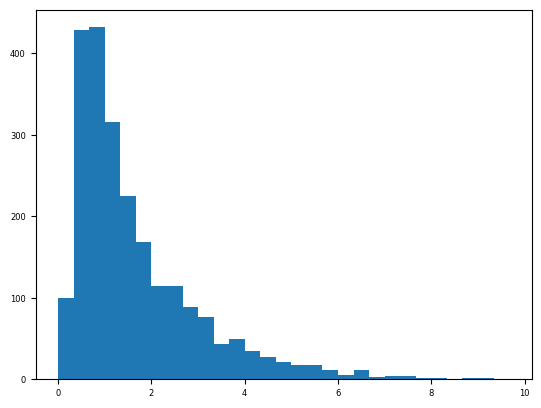

In [987]:
plt.hist(bulk_data_filtered["3km_cot"]/3,np.arange(0,30)/3)

In [244]:
bulk_data_filtered.track_start_time.dt.year.value_counts()

track_start_time
2007    420
2009    335
2010    326
2008    271
2015    241
2016    210
2014    200
2013    154
2012     84
2006     79
Name: count, dtype: int64

## Z_Meas

In [989]:
def extract_bulk_samples_by_time(df):
    Z_meas = {}
    t_meas = {}
    ext_meas = {}
    iwc_meas = {}
    for rel_ind in np.sort(df.rel_ind.unique()):
        Z_meas[rel_ind]=np.vstack(df[df["rel_ind"]==rel_ind]["Z_bulk_means"].to_numpy())
        t_meas[rel_ind]=np.vstack(df[df["rel_ind"]==rel_ind]["temp_bulk_means"].to_numpy())
        iwc_meas[rel_ind]=np.vstack(df[df["rel_ind"]==rel_ind]["iwc_bulk_means"].to_numpy())
        ext_meas[rel_ind]=df[df["rel_ind"]==rel_ind]["ct_depth"].to_numpy()
    return Z_meas, t_meas, iwc_meas, ext_meas

Z_meas, t_meas, iwc_meas , ext_meas = extract_bulk_samples_by_time(bulk_data_filtered)


findfont: Font family 'arial' not found.
findfont: Font family 'arial' not found.
findfont: Font family 'arial' not found.
findfont: Font family 'arial' not found.
findfont: Font family 'arial' not found.
findfont: Font family 'arial' not found.
findfont: Font family 'arial' not found.
findfont: Font family 'arial' not found.
findfont: Font family 'arial' not found.
findfont: Font family 'arial' not found.
findfont: Font family 'arial' not found.
findfont: Font family 'arial' not found.
findfont: Font family 'arial' not found.
findfont: Font family 'arial' not found.
findfont: Font family 'arial' not found.
findfont: Font family 'arial' not found.
findfont: Font family 'arial' not found.
findfont: Font family 'arial' not found.
findfont: Font family 'arial' not found.
findfont: Font family 'arial' not found.
findfont: Font family 'arial' not found.
findfont: Font family 'arial' not found.
findfont: Font family 'arial' not found.
findfont: Font family 'arial' not found.
findfont: Font f

findfont: Font family 'arial' not found.
findfont: Font family 'arial' not found.
findfont: Font family 'arial' not found.
findfont: Font family 'arial' not found.
findfont: Font family 'arial' not found.
findfont: Font family 'arial' not found.
findfont: Font family 'arial' not found.
findfont: Font family 'arial' not found.
findfont: Font family 'arial' not found.
findfont: Font family 'arial' not found.


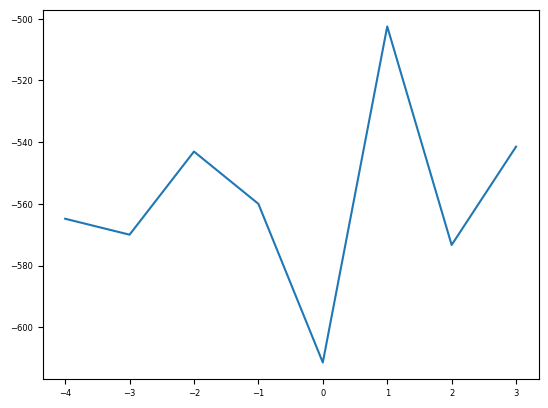

In [247]:
result_ext = []
inds = [i for i in range(-4,4)]
for ind in inds:
   result_ext.append( -ext_meas[ind].mean())
plt.plot(inds,result_ext)

# Correlation data

In [248]:
# corr_peak_ci = pd.read_parquet("/Volumes/University_stuff/Code_Projects/MSGI/plotting/Publication_figures/IF_autocorrelation_values.parquet")
corr_peak_ci = pd.read_parquet("/wolke_scratch/dnikolo/MSGI/plotting/Publication_figures/IF_autocorrelation_values.parquet")

In [249]:
# corr_peak_ci

# Statistics

## Calculate

In [250]:
np.percentile(bulk_data_filtered["avg_size[km]"],90)

51648.48997977119

In [251]:
np.exp(np.mean(np.log(bulk_data_filtered["avg_size[km]"])))

18044.24313799357

In [252]:


inds = np.arange(ind_range[0], ind_range[1])

# Original vertical levels
y_levels = np.asarray(test_row["bulk_level_offset_top_m"])

# New grouped levels using old level indices

level_groups = [
    list(range(0, l2_start)), 
]
level_groups.extend([list(range(l2_start+i*l_depth, l2_start+(i+1)*l_depth)) for i in range(n_agg_levels-1)])

n_levels = len(level_groups)
n_times = len(inds)

mean_map = np.full((n_levels, n_times), np.nan)
std_map  = np.full((n_levels, n_times), np.nan)
n_map    = np.full((n_levels, n_times), np.nan)

# Adjust this if your columns correspond to different relative indices
# rel_times_min = np.array([-45, -30, -15, 0, 15, 30, 45])


# level_labels = [
#     "Cloud top",
#     " -560 to -1360 m ",
#     "-1360 to -2160 m ",
# ]

level_labels = [
    "Cloud top",
    # f" -{l2_start*120} to -{(l2_start+l_depth)*120} m ",
    # f" -{(l2_start+l_depth)*120} to -{(l2_start+2*l_depth)*120} m ",
]

level_labels.extend([f" -{(l2_start+i*l_depth)*120} to -{(l2_start+(i+1)*l_depth)*120} m " for i in range(n_agg_levels-1)])

In [253]:
# --------------------------------------------------------------
# Vertical averaging method
#
# "linear": convert dBZ -> Z, average Z, convert back to dBZ
# "log":    arithmetic mean of dBZ values
# --------------------------------------------------------------

if mean_mode not in {"linear", "log"}:
    raise ValueError(
        "mean_mode must be either 'linear' or 'log'"
    )


def calculate_layer_mean_dbz(dbz_block, mode):
    """
    Calculate one vertically averaged dBZ value per cloud.

    Parameters
    ----------
    dbz_block : ndarray
        Shape: clouds x vertical levels.
    mode : {"linear", "log"}
        "linear": average in linear reflectivity space.
        "log": average dBZ values directly.

    Returns
    -------
    ndarray
        One layer-averaged dBZ value per cloud.
    """
    dbz_block = np.asarray(dbz_block, dtype=float)

    valid_counts = np.sum(
        np.isfinite(dbz_block),
        axis=1,
    )

    if mode == "linear":
        linear_z = 10.0 ** (dbz_block / 10.0)

        mean_linear_z = np.divide(
            np.nansum(linear_z, axis=1),
            valid_counts,
            out=np.full(dbz_block.shape[0], np.nan),
            where=valid_counts > 0,
        )

        cloud_values = 10.0 * np.log10(mean_linear_z)

    else:  # mode == "log"
        cloud_values = np.divide(
            np.nansum(dbz_block, axis=1),
            valid_counts,
            out=np.full(dbz_block.shape[0], np.nan),
            where=valid_counts > 0,
        )
    

    return cloud_values


dbZ_grouped_by_ind = {}
cloud_group_values_by_ind = {}

for col, ind in enumerate(inds):
    dbZ = np.asarray(
        Z_meas[ind],
        dtype=float,
    ).copy()

    dbZ[~np.isfinite(dbZ)] = np.nan

    # Shape: clouds x grouped vertical levels
    cloud_group_matrix = np.full(
        (dbZ.shape[0], n_levels),
        np.nan,
    )

    grouped_dbZ = []

    for i, group in enumerate(level_groups):
        cloud_values = calculate_layer_mean_dbz(
            dbZ[:, group],
            mode=mean_mode,
        )

        # Preserve row alignment for cloud-level bootstrapping
        cloud_group_matrix[:, i] = cloud_values

        # Finite sample used for statistics
        finite_values = cloud_values[
            np.isfinite(cloud_values)
        ]

        grouped_dbZ.append(finite_values)

        if len(finite_values) >= 1:
            mean_map[i, col] = np.mean(finite_values)
            n_map[i, col] = len(finite_values)

        if len(finite_values) >= 2:
            std_map[i, col] = np.std(
                finite_values,
                ddof=1,
            )

    dbZ_grouped_by_ind[ind] = grouped_dbZ
    cloud_group_values_by_ind[ind] = cloud_group_matrix

sem_map = std_map / np.sqrt(n_map)

In [254]:
ind_range[0]

-3

In [255]:
mean_map

array([[-16.07722697, -15.73945557, -16.47735396, -17.10095298,
        -15.60875396, -15.8484014 , -16.18949316],
       [ -9.14422867,  -8.60965445,  -9.46579982, -10.62198532,
         -8.35855959,  -8.34611565,  -9.25872853],
       [ -5.61277145,  -5.48390411,  -5.19344635,  -6.69958297,
         -4.42205726,  -3.58934029,  -5.20303185]])

In [256]:
"""
Correlation-weighted pooled deviations.

Drop-in replacement for the Welch-test loop and the bootstrap block.
Assumes the following already exist from your current code:

    inds, n_levels, n_times, mean_map, std_map, n_map,
    dbZ_grouped_by_ind, cloud_group_values_by_ind,
    iqr_filter_x, iqr_filter_y, n_bootstrap, confidence_level,
    corr_peak_ci  (DataFrame with rel_ind, corr_with_peak)
"""

from scipy.stats import t



# ------------------------------------------------------------------
# 1. Build one scalar weight per time index
# ------------------------------------------------------------------
def build_index_weights(
    corr_table,
    inds,
    peak_ind,
    mode=WEIGHT_MODE,
    floor=WEIGHT_FLOOR,
    invert=INVERT_WEIGHTS,
):
    """Map each absolute index in `inds` to a weight derived from rho."""

    if peak_ind is None:
        raise ValueError("PEAK_IND must be set (absolute index of rel_ind == 0)")

    rho_lookup = dict(
        zip(
            corr_table["rel_ind"].astype(int),
            corr_table["corr_with_peak"].astype(float),
        )
    )

    weights = {}

    for ind in inds:
        rel = int(ind) - int(peak_ind)
        rho = rho_lookup.get(rel, np.nan)
        if mode=="none":
            weights[ind] = 1.0
            continue
        elif not np.isfinite(rho):
            # No correlation estimate for this lag: fall back to floor
            weights[ind] = max(floor, 0.0)
            continue

        rho = float(np.clip(rho, -1.0, 1.0))

        if mode == "residual":
            redundancy = rho ** 2
        elif mode == "abs":
            redundancy = abs(rho)
        elif mode == "signed":
            redundancy = max(rho, 0.0)
        elif mode == "none":
            redundancy = 0.0
        else:
            raise ValueError(f"unknown WEIGHT_MODE: {mode}")

        w = redundancy if invert else 1.0 - redundancy
        weights[ind] = max(float(w), floor)

    if EQUALISE_INDEX_SIZE:
        for ind in inds:
            n_clouds = cloud_group_values_by_ind[ind].shape[0]
            if n_clouds > 0:
                weights[ind] /= n_clouds

    # Rescale to mean 1. Purely cosmetic: weighted means and n_eff are
    # both scale invariant, so this changes nothing numerically.
    scale = np.mean(list(weights.values()))
    if scale > 0:
        weights = {k: v / scale for k, v in weights.items()}

    return weights


index_weights = build_index_weights(corr_peak_ci, inds, PEAK_IND)


# ------------------------------------------------------------------
# 2. Weighted moments
# ------------------------------------------------------------------
def weighted_moments(values, weights):
    """
    Weighted mean, unbiased weighted variance, and Kish effective n.

    Uses reliability weights, so the variance denominator reduces to
    (n - 1) when all weights are equal. The variance of the weighted
    mean is then simply var / n_eff.
    """
    v = np.asarray(values, dtype=float)
    w = np.asarray(weights, dtype=float)

    ok = np.isfinite(v) & np.isfinite(w) & (w > 0)
    v, w = v[ok], w[ok]

    if v.size == 0:
        return np.nan, np.nan, 0.0

    sw = w.sum()
    mean = np.sum(w * v) / sw
    n_eff = sw ** 2 / np.sum(w ** 2)

    if v.size < 2 or n_eff <= 1:
        return mean, np.nan, n_eff

    denom = sw - np.sum(w ** 2) / sw
    var = np.sum(w * (v - mean) ** 2) / denom

    return mean, var, n_eff


def iqr_mask(x, k=1.5):
    """Boolean keep-mask, so weights stay aligned with values."""
    x = np.asarray(x, dtype=float)
    finite = np.isfinite(x)

    if finite.sum() < 4:
        return finite

    q1, q3 = np.nanpercentile(x[finite], [25, 75])
    iqr = q3 - q1

    if iqr == 0 or not np.isfinite(iqr):
        return finite

    return finite & (x >= q1 - k * iqr) & (x <= q3 + k * iqr)


# ------------------------------------------------------------------
# 3. Welch loop against a correlation-weighted reference
# ------------------------------------------------------------------
p_welch_map = np.full_like(mean_map, np.nan)
dev_vs_others_map = np.full_like(mean_map, np.nan)
effect_size_map = np.full_like(mean_map, np.nan)

n_x_map = np.full_like(mean_map, np.nan)
n_y_raw_map = np.full_like(mean_map, np.nan)
n_y_clean_map = np.full_like(mean_map, np.nan)
n_y_eff_map = np.full_like(mean_map, np.nan)

for j, ind in enumerate(inds):
    x_groups = dbZ_grouped_by_ind[ind]
    other_inds = [k for k in inds if k != ind]

    for i in range(n_levels):
        x = x_groups[i]
        x = x[np.isfinite(x)]

        # Pool the same grouped level from all other time indices,
        # carrying each index's weight alongside its values.
        y_parts, w_parts = [], []
        for k in other_inds:
            vals = dbZ_grouped_by_ind[k][i]
            vals = vals[np.isfinite(vals)]
            if vals.size == 0:
                continue
            y_parts.append(vals)
            w_parts.append(np.full(vals.size, index_weights[k]))

        if not y_parts:
            continue

        y = np.concatenate(y_parts)
        wy = np.concatenate(w_parts)

        n_y_raw = y.size

        if iqr_filter_y:
            keep = iqr_mask(y, k=1.5)
            y, wy = y[keep], wy[keep]
        if iqr_filter_x:
            keep = iqr_mask(x, k=1.5)
            x = x[keep]

        if x.size < 2 or y.size < 2:
            continue

        # x carries a single weight, so weighted == unweighted here.
        mx = np.mean(x)
        vx = np.var(x, ddof=1)
        nx = x.size

        my, vy, ny_eff = weighted_moments(y, wy)

        if not np.isfinite(vy) or ny_eff <= 1:
            continue

        dev = mx - my
        se = np.sqrt(vx / nx + vy / ny_eff)

        if se == 0 or not np.isfinite(se):
            continue

        tval = dev / se

        df_num = (vx / nx + vy / ny_eff) ** 2
        df_den = (
            ((vx / nx) ** 2) / (nx - 1)
            + ((vy / ny_eff) ** 2) / (ny_eff - 1)
        )

        if df_den == 0 or not np.isfinite(df_den):
            continue

        df = df_num / df_den
        p = 2 * t.sf(np.abs(tval), df)

        pooled_sd = np.sqrt((vx + vy) / 2)

        p_welch_map[i, j] = p
        dev_vs_others_map[i, j] = dev

        if pooled_sd > 0 and np.isfinite(pooled_sd):
            effect_size_map[i, j] = dev / pooled_sd

        n_x_map[i, j] = nx
        n_y_raw_map[i, j] = n_y_raw
        n_y_clean_map[i, j] = y.size
        n_y_eff_map[i, j] = ny_eff

sem_map = std_map / np.sqrt(n_map)


# ------------------------------------------------------------------
# 4. Bootstrap with the same weighting
# ------------------------------------------------------------------
def calculate_pooled_deviations(cloud_arrays, inds, n_levels, weights):
    """Deviation of each time mean from the weighted pool of all others."""

    n_times = len(inds)
    deviations = np.full((n_levels, n_times), np.nan)

    for j, ind in enumerate(inds):
        other_inds = [k for k in inds if k != ind]

        for i in range(n_levels):
            x = cloud_arrays[ind][:, i]
            x = x[np.isfinite(x)]

            y_parts, w_parts = [], []
            for k in other_inds:
                vals = cloud_arrays[k][:, i]
                vals = vals[np.isfinite(vals)]
                if vals.size == 0:
                    continue
                y_parts.append(vals)
                w_parts.append(np.full(vals.size, weights[k]))

            if x.size == 0 or not y_parts:
                continue

            y = np.concatenate(y_parts)
            wy = np.concatenate(w_parts)

            deviations[i, j] = np.mean(x) - np.sum(wy * y) / wy.sum()

    return deviations


rng = np.random.default_rng(42)

index_bootstrap = np.full((n_bootstrap, n_times - 1), np.nan)

for b in range(n_bootstrap):
    bootstrap_arrays = {}

    for ind in inds:
        values = cloud_group_values_by_ind[ind]
        n_clouds = values.shape[0]

        # Resample complete cloud rows
        sample_indices = rng.integers(0, n_clouds, size=n_clouds)
        bootstrap_arrays[ind] = values[sample_indices]

    bootstrap_deviations = calculate_pooled_deviations(
        bootstrap_arrays,
        inds,
        n_levels,
        index_weights,
    )

    index_bootstrap[b] = (
        bootstrap_deviations[1, :-1] + bootstrap_deviations[2, 1:]
    )

if not 0 < confidence_level < 1:
    raise ValueError("confidence_level must be between 0 and 1")

alpha = 1.0 - confidence_level
lower_percentile = 100.0 * alpha / 2.0
upper_percentile = 100.0 * (1.0 - alpha / 2.0)

sedimentation_index = (
    dev_vs_others_map[1, :-1] + dev_vs_others_map[2, 1:]
)

(
    sedimentation_index_ci_low,
    sedimentation_index_ci_high,
) = np.nanpercentile(
    index_bootstrap,
    [lower_percentile, upper_percentile],
    axis=0,
)


# ------------------------------------------------------------------
# 5. Sanity check: how much did the weighting move things?
# ------------------------------------------------------------------
if __name__ == "__main__":
    for ind in inds:
        rel = int(ind) - int(PEAK_IND)
        print(f"ind {ind:>4}  rel {rel:>3}  w = {index_weights[ind]:.3f}")

    print("\neffective vs raw n for the pooled reference:")
    print(np.round(n_y_eff_map / n_y_clean_map, 3))

ind   -3  rel  -3  w = 1.000
ind   -2  rel  -2  w = 1.000
ind   -1  rel  -1  w = 1.000
ind    0  rel   0  w = 1.000
ind    1  rel   1  w = 1.000
ind    2  rel   2  w = 1.000
ind    3  rel   3  w = 1.000

effective vs raw n for the pooled reference:
[[1. 1. 1. 1. 1. 1. 1.]
 [1. 1. 1. 1. 1. 1. 1.]
 [1. 1. 1. 1. 1. 1. 1.]
 [1. 1. 1. 1. 1. 1. 1.]]


# Bulk Plot

## Set style

In [257]:
import matplotlib.gridspec as gridspec
import cmcrameri
import matplotlib.font_manager as fm
import matplotlib as mpl
from matplotlib.colors import TwoSlopeNorm

In [258]:

%matplotlib inline
plt.rc('font',family='arial')
plt.rcParams.update({"font.size":6})
font= fm.FontProperties(family='arial')
mpl.rcParams['pdf.fonttype'] = 42
mpl.rcParams['ps.fonttype'] = 42
# cmcrameri.cm.show_cmaps()



In [1002]:
classifiacation_palette = cmcrameri.cm.actonS.colors[[i for i in range(10) if i != 1],:]

## Bulk publication figure

In [1003]:
dev_vs_others_map.max()

np.float64(1.7729804299333796)

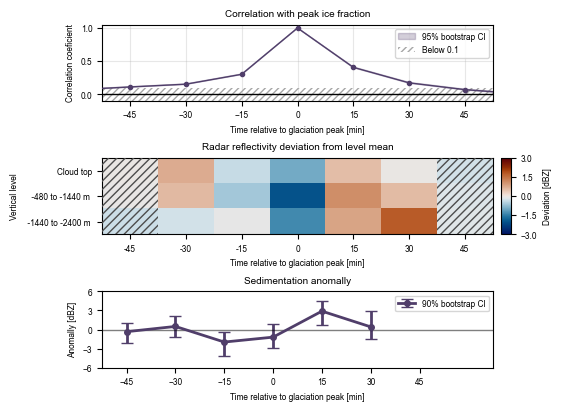

In [1004]:

# fig = plt.figure(figsize=(6.69291, 6.69291*3.504/5.501), constrained_layout=True) 170 mm
fig = plt.figure(figsize=(5.501, 4), constrained_layout=True)#5.501*3.504/5.501), constrained_layout=True)
gs = gridspec.GridSpec(3, 3,height_ratios=[1, 1,1], width_ratios=[1,1,0.05],figure=fig)#,hspace=1.2, wspace=0.3)#,
ax_heat = fig.add_subplot(gs[1, :2])
ax_top_cb = fig.add_subplot(gs[1, 2])
ax_anom = fig.add_subplot(gs[2, :2])
ax_corr = fig.add_subplot(gs[0, :2])


# Common axes formatting
for ax in (ax_heat,):
    ax.set_xticks(np.arange(len(rel_times_min)))
    ax.set_xticklabels(rel_times_min)
    ax.set_yticks(np.arange(len(level_labels)))
    ax.set_yticklabels(level_labels)
    ax.set_ylabel("Vertical level")
    ax.set_xlabel("Time relative to glaciation peak [min]")

vmax = np.nanmax(np.abs(dev_vs_others_map))



ax_heat.set_title("Radar reflectivity deviation from level mean")

im1 = ax_heat.imshow(
    dev_vs_others_map,
    aspect="auto",
    cmap=cm.vik,
    norm=TwoSlopeNorm(vmin=-3, vcenter=0, vmax=3),
    origin="upper",
)

cbar = fig.colorbar(im1, cax=ax_top_cb)
cbar.set_label("Deviation [dBZ]")  # Adjust units/label as needed
cbar.set_ticks([-3, -1.5, 0, 1.5, 3])
index_times = rel_times_min[:-1]

ci_percent = 100 * confidence_level
# ax_anom
ax_anom.errorbar(
    index_times,
    sedimentation_index,
    yerr=np.vstack([
        np.maximum(
            sedimentation_index - sedimentation_index_ci_low,
            0,
        ),
        np.maximum(
            sedimentation_index_ci_high - sedimentation_index,
            0,
        ),
    ]),
    marker="o",
    linewidth=2,
    markersize=4,
    capsize=4,
    label=f"{ci_percent:g}% bootstrap CI",
    color=classifiacation_palette[4]
)

ax_anom.legend()
ax_anom.axhline(
    0,
    color="k",
    linewidth=1,
    alpha=0.5,
)

ax_anom.set_xticks(rel_times_min)
ax_anom.set_xlabel("Time relative to glaciation peak [min]")
ax_anom.set_ylabel("Anomally [dBZ]")
ax_anom.set_title("Sedimentation anomally")
ax_anom.set_xlim(ind_range[0]*15-7.5,+ind_range[1]*15+7.5)
ax_anom.set_ylim(-6,6)
ax_anom.set_yticks(np.arange(-6,7,3))
ax_anom.legend(loc="upper right")


ax_corr.plot(
    corr_peak_ci["rel_time_min"],
    corr_peak_ci["corr_with_peak"],
    marker="o",
    markersize=3,
    linewidth=1,
    # label="Correlation with peak",
    zorder=3,
    color=classifiacation_palette[4]
)

ax_corr.fill_between(
    corr_peak_ci["rel_time_min"],
    corr_peak_ci["ci_low"],
    corr_peak_ci["ci_high"],
    alpha=0.25,
    label="95% bootstrap CI",
    zorder=2,
    color=classifiacation_palette[4]
)

# ax_corr.axvline(
#     0,
#     color="k",
#     linestyle="--",
#     linewidth=1,
#     label="Glaciation peak",
#     zorder=4,
# )

ax_corr.axhline(
    0,
    color="k",
    linewidth=1,
    zorder=4,
)

# Hatched region: correlation below 0.1
ax_corr.axhspan(
    -0.1,
    0.1,
    facecolor="none",
    edgecolor="0.65",
    hatch="/////",
    linewidth=0,
    zorder=0,
    label="Below 0.1",
)


# Find index positions of -45 and +45 min in the heatmap's x-axis
rel_times_arr = np.asarray(rel_times_min)
idx_m45 = np.where(rel_times_arr == -45)[0]
idx_p45 = np.where(rel_times_arr == 45)[0]

for idx in np.concatenate([idx_m45, idx_p45]):
    ax_heat.axvspan(
        idx - 0.5, idx + 0.5,
        facecolor="none",
        edgecolor="0.3",
        hatch="////",
        linewidth=0,
        zorder=5,
    )
# Label every 15-minute sample
xmin = corr_peak_ci["rel_time_min"].min()
xmax = corr_peak_ci["rel_time_min"].max()

xticks = np.arange(
    np.floor(xmin / 15) * 15,
    np.ceil(xmax / 15) * 15 + 15,
    15,
)

ax_corr.set_xticks(xticks)
ax_corr.set_xlim(xmin, xmax)
ax_corr.set_xlim(ind_range[0]*15-7.5,(ind_range[1]-1)*15+7.5)


ax_corr.set_xlabel("Time relative to glaciation peak [min]")
ax_corr.set_ylabel("Correlation coeficient")
ax_corr.set_title("Correlation with peak ice fraction")
ax_corr.set_ylim(-0.1, 1.05)

ax_corr.grid(alpha=0.3)
ax_corr.legend()


# fig.savefig(
#     "/Volumes/University_stuff/Code_Projects/MSGI/plotting/Publication_figures/Bulk_figure.pdf",
#     format="pdf",
#     dpi=300
# )

In [261]:
mean_map

array([[-15.84201388, -16.01609518, -16.4791301 , -17.10131654,
        -15.61702357, -15.97704784, -16.46160716],
       [ -9.22453443,  -9.44999494,  -9.80603348, -10.67267028,
         -8.68406263,  -8.86159458,  -9.87034411],
       [ -5.23386703,  -6.09786173,  -5.60848122,  -6.26675493,
         -4.54683384,  -4.04571291,  -5.5236394 ],
       [ -3.71281206,  -4.54722398,  -3.35949106,  -2.67836649,
         -2.13747227,  -2.26558484,  -1.45367701]])

In [262]:
bulk_data_filtered["ct_depth"].mean()

518.4310344827586

## Save data 

In [263]:
from pathlib import Path
import numpy as np
import pandas as pd

output_dir = Path(
    "/Volumes/University_stuff/Code_Projects/MSGI/plotting/Publication_figures/data/observations"
)
output_dir.mkdir(parents=True, exist_ok=True)


# 1. Heatmap data — one row per heatmap cell
heatmap_values = np.asarray(dev_vs_others_map)

if heatmap_values.shape != (len(level_labels), len(rel_times_min)):
    raise ValueError(
        "Heatmap dimensions do not match level_labels and rel_times_min: "
        f"{heatmap_values.shape} != "
        f"({len(level_labels)}, {len(rel_times_min)})"
    )

heatmap_df = (
    pd.DataFrame(
        heatmap_values,
        index=level_labels,
        columns=rel_times_min,
    )
    .rename_axis(index="vertical_level", columns="rel_time_min")
    .stack()
    .rename("reflectivity_deviation_dbz")
    .reset_index()
)

heatmap_df.to_csv(
    output_dir / "reflectivity_deviation_heatmap.csv",
    index=False,
)


# 2. Sedimentation anomaly and confidence interval
index_times = np.asarray(rel_times_min[:-1])
sedimentation_index_arr = np.asarray(sedimentation_index)
sedimentation_ci_low_arr = np.asarray(sedimentation_index_ci_low)
sedimentation_ci_high_arr = np.asarray(sedimentation_index_ci_high)

lengths = {
    len(index_times),
    len(sedimentation_index_arr),
    len(sedimentation_ci_low_arr),
    len(sedimentation_ci_high_arr),
}
if len(lengths) != 1:
    raise ValueError(
        "Sedimentation arrays and index_times must have equal lengths."
    )

anomaly_df = pd.DataFrame({
    "rel_time_min": index_times,
    "sedimentation_anomaly_dbz": sedimentation_index_arr,
    "ci_low_dbz": sedimentation_ci_low_arr,
    "ci_high_dbz": sedimentation_ci_high_arr,
})

anomaly_df.to_csv(
    output_dir / "sedimentation_anomaly.csv",
    index=False,
)


# 3. Correlation and confidence interval
correlation_df = corr_peak_ci[
    ["rel_time_min", "corr_with_peak", "ci_low", "ci_high"]
].copy()

correlation_df.to_csv(
    output_dir / "peak_ice_fraction_correlation.csv",
    index=False,
)

# 1. Mean reflectivity — one row per heatmap cell
mean_values = np.asarray(mean_map)

expected_shape = (len(level_labels), len(rel_times_min))
if mean_values.shape != expected_shape:
    raise ValueError(
        "Mean-map dimensions do not match level_labels and rel_times_min: "
        f"{mean_values.shape} != {expected_shape}"
    )

mean_reflectivity_df = (
    pd.DataFrame(
        mean_values,
        index=level_labels,
        columns=rel_times_min,
    )
    .rename_axis(index="vertical_level", columns="rel_time_min")
    .stack()
    .rename("reflectivity_dbz")
    .reset_index()
)

mean_reflectivity_df.to_csv(
    output_dir / "mean_reflectivity.csv",
    index=False,
)

PermissionError: [Errno 13] Permission denied: '/Volumes'

In [ ]:
import json
import platform
from datetime import datetime, timezone

metadata = {
    "created_utc": datetime.now(timezone.utc).isoformat(),
    "settings": {
        "l2_start": int(l2_start),
        "l_depth": int(l_depth),
        "iqr_filter_y": bool(iqr_filter_y),
        "iqr_filter_x": bool(iqr_filter_x),
        "ind_range": [int(x) for x in ind_range],
        "rel_times_min": np.asarray(rel_times_min, dtype=int).tolist(),
        "timesteps": [int(x) for x in timesteps],
        "mean_mode": str(mean_mode),
        "confidence_level": float(confidence_level),
        "confidence_level_percent": float(confidence_level * 100),
        "n_bootstrap": int(n_bootstrap),
        "peak_ind": int(PEAK_IND),
        "weight_mode": str(WEIGHT_MODE),
        "weight_floor": float(WEIGHT_FLOOR),
        "invert_weights": bool(INVERT_WEIGHTS),
        "equalise_index_size": bool(EQUALISE_INDEX_SIZE),
    },
    "files": {
        "mean_reflectivity.csv": {
            "description": (
                "Radar reflectivity means."
            ),
            "columns": {
                "vertical_level": "Vertical-level label",
                "rel_time_min": (
                    "Time relative to the glaciation peak in minutes"
                ),
                "reflectivity_dbz": (
                    "Radar reflectivity in dBZ"
                ),
            },
        },
        "reflectivity_deviation_heatmap.csv": {
            "description": (
                "Radar reflectivity deviation from the vertical-level mean."
            ),
            "columns": {
                "vertical_level": "Vertical-level label",
                "rel_time_min": (
                    "Time relative to the glaciation peak in minutes"
                ),
                "reflectivity_deviation_dbz": (
                    "Radar reflectivity deviation in dBZ"
                ),
            },
        },
        "sedimentation_anomaly.csv": {
            "description": (
                "Sedimentation anomaly with bootstrap confidence interval."
            ),
            "columns": {
                "rel_time_min": (
                    "Time relative to the glaciation peak in minutes"
                ),
                "sedimentation_anomaly_dbz": (
                    "Sedimentation anomaly in dBZ"
                ),
                "ci_low_dbz": "Lower bootstrap confidence limit in dBZ",
                "ci_high_dbz": "Upper bootstrap confidence limit in dBZ",
            },
        },
        "peak_ice_fraction_correlation.csv": {
            "description": (
                "Correlation with peak ice fraction and bootstrap "
                "confidence interval."
            ),
            "columns": {
                "rel_time_min": (
                    "Time relative to the glaciation peak in minutes"
                ),
                "corr_with_peak": "Correlation coefficient",
                "ci_low": "Lower bootstrap confidence limit",
                "ci_high": "Upper bootstrap confidence limit",
            },
        },
    },
    "software": {
        "python": platform.python_version(),
        "numpy": np.__version__,
        "pandas": pd.__version__,
    },
}

with open(output_dir / "metadata.json", "w", encoding="utf-8") as metadata_file:
    json.dump(
        metadata,
        metadata_file,
        indent=2,
        ensure_ascii=False,
        allow_nan=False,
    )

In [ ]:
vmax = np.nanmax(np.abs(dev_vs_others_map))
vmin = -vmax

print("vmin:", vmin)
print("vmax:", vmax)

vmin: -2.033353765252464
vmax: 2.033353765252464


## Bias-source publication figure


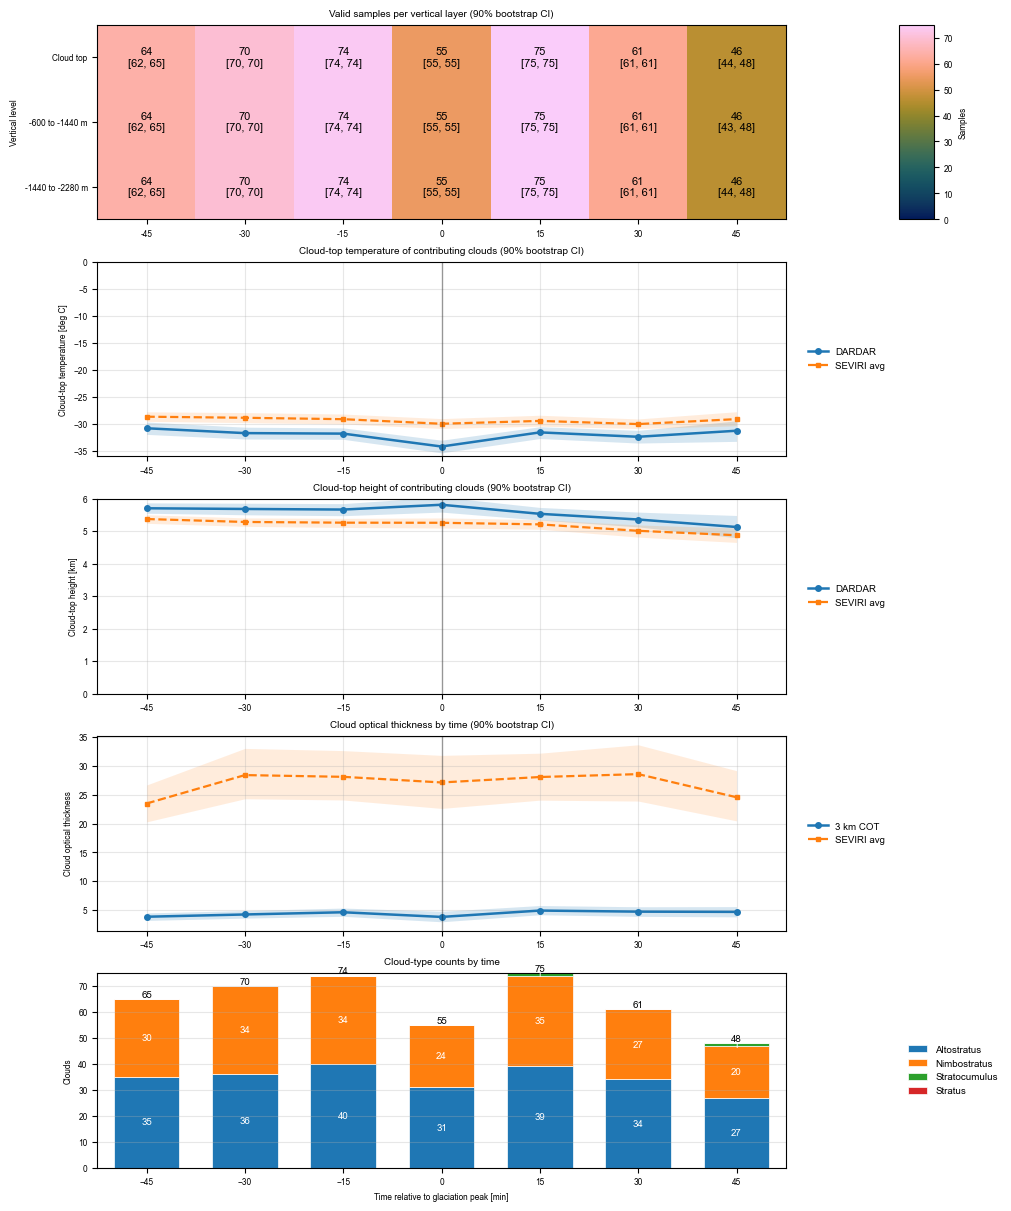

In [ ]:
# Run in a separate namespace so the three-level figure cannot overwrite
# this notebook's n_map, n_levels, level_groups, or analysis settings.
def generate_bias_sources_figure():
    import runpy

    runpy.run_path(
        "/Volumes/University_stuff/Code_Projects/MSGI/plotting/Bulk/bias_sources_publication_figure.py",
        run_name="__main__",
    )


generate_bias_sources_figure()


In [ ]:
bulk_data_filtered["ct_depth"].mean()

np.float64(517.9479971890372)

In [ ]:
bulk_data_filtered["ct_depth"].mean()/120

np.float64(4.316233309908643)

In [ ]:
bulk_data_filtered["Cloud type"].value_counts()

Cloud type
Altostratus      1377
Nimbostratus     1257
Altocumulus        33
Stratocumulus      31
Stratus             8
Cumulus             6
Name: count, dtype: int64

In [ ]:
n_y_clean_map

array([[374., 369., 362., 389., 370., 382., 394.],
       [383., 378., 370., 400., 375., 390., 403.],
       [382., 378., 369., 401., 375., 388., 403.]])

In [ ]:
n_x_map

array([[66., 71., 78., 50., 71., 59., 46.],
       [67., 72., 79., 49., 73., 60., 47.],
       [66., 71., 80., 49., 74., 61., 47.]])

In [ ]:
bulk_data_filtered["ct_depth"].mean()/120

np.float64(4.316233309908643)

In [ ]:
bulk_data_filtered.iloc[0]["Z_bulk_means"]

array([-19.076298 , -16.088455 , -13.392471 , -11.270064 ,  -9.405037 ,
        -7.7233386,  -6.2596865,  -5.0125785,  -3.7417407,  -2.638119 ,
        -2.0838084,  -2.0461843,  -2.5445316,  -3.3624763,  -4.716188 ,
        -5.942751 ,  -7.5593486,  -9.166061 , -10.989412 , -12.525781 ,
       -14.48649  , -16.871851 , -18.898174 , -21.166367 , -23.485615 ],
      dtype=float32)

In [ ]:
# plt.hist()
bulk_data_filtered.track_start_time.dt.year.value_counts()

track_start_time
2007    516
2009    422
2010    393
2008    327
2015    294
2016    253
2014    245
2013    190
2012    111
2006     95
Name: count, dtype: int64

# IF plot

In [ ]:
colormap=cm.lipariS.colors
color_dd=colormap[2]
color_sev=colormap[3]
color_mod=colormap[0]


In [ ]:
# dd_data_list = []
# for year in range(2007,2009):
#     dd_data_list.append(pd.read_parquet("/Volumes/University_stuff/Code_Projects/MSGI/Bulk_data/02/glaciations_with_bulk_data_V3_1_2007.parquet"))
df_glac_dd = bulk_data_colocated[bulk_data_colocated["avg_ctp"]>440]
df_glac_dd = df_glac_dd[df_glac_dd["ct_depth"]<1000]
# df_glac_dd= df_glac_dd[df_glac_dd["3km_cot"]>0.6]
df_glac_dd = df_glac_dd[df_glac_dd["continious_cloud"]]
# df_glac_dd = bulk_data_filtered

In [ ]:
def get_seviri_peak_if(row):
    if_hist = row["val_pix_claas_if_hist"]
    return if_hist[row["Glac_peak_ind"]]

def get_if_glac_peak_same_cloud(row):
    if_hist = row["val_ice_frac_hist"]
    peak_value = if_hist[row["Glac_peak_ind"]]   
    if peak_value >=0:
        return peak_value
    else:
        return np.nan
    
def get_claas_if_glac_peak_same_cloud(row):
    if_hist = row["val_pix_claas_if_hist"]
    peak_value = if_hist[row["Glac_peak_ind"]]   
    
    if peak_value >=0:
        return peak_value
    else:
        return np.nan
    
def get_seviri_pre_peak_if(row: pd.Series,idx: int):
    if_hist = row["ice_frac_hist"]
    if ((row["Glac_peak_ind"]-idx)>=0) and ((row["Glac_peak_ind"]-idx)<len(if_hist)):
        return if_hist[row["Glac_peak_ind"]-idx]
    return np.nan

# def get_dd_pre_peak_if(row: pd.Series,idx: int):
#     if_hist = row["val_ice_frac_hist"]
#     if ((row["Glac_peak_ind"]-idx)>=0) and ((row["Glac_peak_ind"]-idx)<len(if_hist)):
#         if if_hist[row["Glac_peak_ind"]-idx]>0:
#             return row["cph_bulk_means"][0].mean()-1
#         return np.nan
#     return np.nan

def get_dd_pre_peak_if(row: pd.Series,idx: int):
    if_hist = row["val_ice_frac_hist"]
    if ((row["Glac_peak_ind"]-idx)>=0) and ((row["Glac_peak_ind"]-idx)<len(if_hist)):
        if if_hist[row["Glac_peak_ind"]-idx]>=-eps:
            if int((row["colocation_time"]-row["track_start_time"])/pd.Timedelta(minutes=15))==(row["Glac_peak_ind"]-idx):
                return if_hist[row["Glac_peak_ind"]-idx]
        return np.nan
    return np.nan


def check_cph_validity(row: pd.Series):   
    ind = int((row["colocation_time"]-row["track_start_time"])/pd.Timedelta(minutes=15))
    if np.isnan(int(row["val_ice_frac_hist"][ind])):
        raise TypeError("Weird error ") 
    return row["cph_bulk_means"][0].mean()-1 - row["val_ice_frac_hist"][ind]

In [ ]:
bulk_data_df_split.apply(check_cph_validity,axis=1).mean()

np.float64(0.0022375894188065367)

(array([5.0000e+00, 8.0000e+00, 2.7000e+01, 1.1100e+02, 1.1060e+03,
        1.3154e+04, 1.3860e+03, 1.9300e+02, 2.7000e+01, 8.0000e+00]),
 array([-0.82142854, -0.67240534, -0.52338214, -0.37435894, -0.22533574,
        -0.07631254,  0.07271066,  0.22173386,  0.37075706,  0.51978025,
         0.66880345]),
 <BarContainer object of 10 artists>)

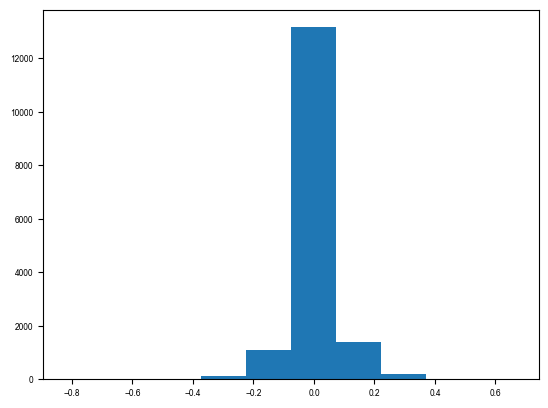

In [ ]:
plt.hist(bulk_data_df_split.apply(check_cph_validity,axis=1))

In [ ]:
np.nanmean(np.concat(bulk_data_colocated["cph_bulk_means"].to_numpy()).reshape(bulk_data_colocated.shape[0],25),axis=0)


array([1.8056823, 1.8207481, 1.859334 , 1.9018887, 1.9169805, 1.9249521,
       1.9326386, 1.9394345, 1.9443824, 1.946165 , 1.9462628, 1.946058 ,
       1.9465252, 1.9455482, 1.943518 , 1.9425644, 1.9387995, 1.9351066,
       1.9323713, 1.9286737, 1.9244273, 1.9190425, 1.9132015, 1.9049772,
       1.8975257], dtype=float32)

In [ ]:
bulk_data_colocated.iloc[10]["cph_bulk_means"]

array([1.9894654, 1.9912597, 1.9946092, 1.9851753, 1.9973047, 1.9878707,
       1.9739892, 1.9122641, 1.8700892, 1.8869047, 1.9288689, 1.9434524,
       1.9821428, 1.9917763, 1.9981203, 1.9924812, 1.9915966, 1.9890109,
       2.       , 2.       , 2.       , 2.       , 2.       , 2.       ,
       2.       ], dtype=float32)

In [1028]:
dev_vs_others_map

array([[-0.0328682 ,  0.74345521, -0.37220889, -0.98238669,  0.53815448,
        -0.0433293 , -0.26186879],
       [-0.06173818,  0.57384305, -0.62478057, -2.03335377,  1.11328611,
         0.55498313, -0.18652769],
       [-0.31045719, -0.27700328, -0.08760763, -1.34106656,  0.83740397,
         1.77298043, -0.14135158]])

In [1029]:
for pre_peak_idx in range(-5, 5):
    # df_glac_mod[f"seviri_{pre_peak_idx}_prepeak_if"] = df_glac_mod.apply(
    #     get_seviri_pre_peak_if,
    #     axis=1,
    #     args=(pre_peak_idx,)
    # )
    df_glac_dd[f"seviri_{pre_peak_idx}_prepeak_if"] = df_glac_dd.apply(
        get_seviri_pre_peak_if,
        axis=1,
        args=(pre_peak_idx,)
    )
    df_glac_dd[f"val_{pre_peak_idx}_prepeak_if"] = df_glac_dd.apply(
        get_dd_pre_peak_if,
        axis=1,
        args=(pre_peak_idx,)
    )
    # df_glac_mod[f"val_{pre_peak_idx}_prepeak_if"] = df_glac_mod.apply(
    #         get_dd_pre_peak_if,
    #         axis=1,
    #         args=(pre_peak_idx,)
    #     )
    

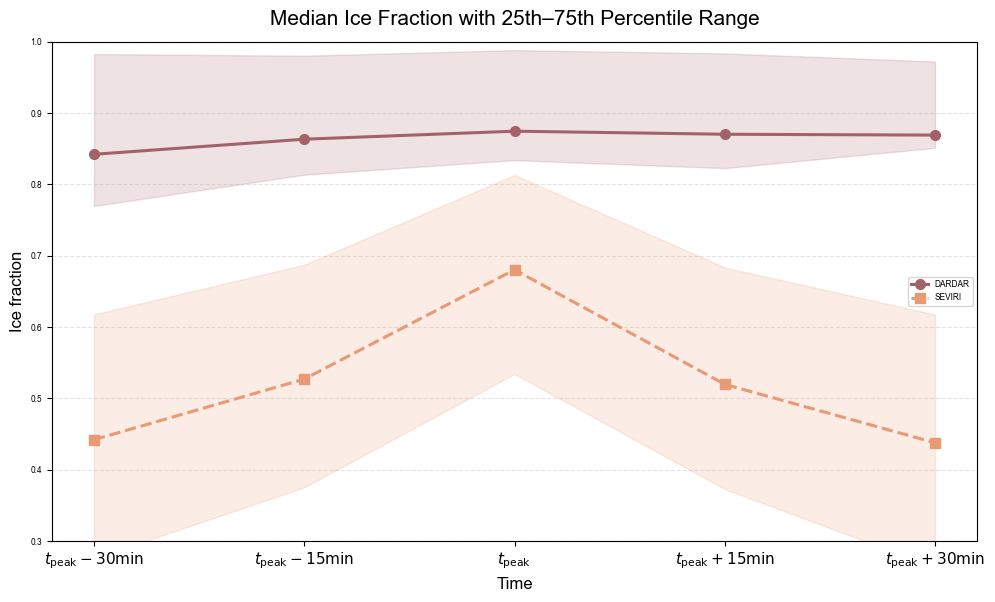

In [ ]:
import numpy as np
import matplotlib.pyplot as plt

# timesteps in plotting order


# corresponding column names
dardar_cols = [f"val_{i}_prepeak_if" for i in timesteps]
# modis_cols  = [f"val_{i}_prepeak_if" for i in timesteps]
seviri_cols = [f"seviri_{i}_prepeak_if" for i in timesteps]

x_labels = [
    # r"$t_{\mathrm{peak}}-45\mathrm{min}$",
    r"$t_{\mathrm{peak}}-30\mathrm{min}$",
    r"$t_{\mathrm{peak}}-15\mathrm{min}$",
    r"$t_{\mathrm{peak}}$",
    r"$t_{\mathrm{peak}}+15\mathrm{min}$",
    r"$t_{\mathrm{peak}}+30\mathrm{min}$",
    # r"$t_{\mathrm{peak}}+45\mathrm{min}$",
]

# x_labels = [
#     "$t_{\\mathrm{peak}}$\n$-30\\,\\mathrm{min}$",
#     "$t_{\\mathrm{peak}}$\n$-15\\,\\mathrm{min}$",
#     "$t_{\\mathrm{peak}}$",
#     "$t_{\\mathrm{peak}}$\n$+15\\,\\mathrm{min}$",
#     "$t_{\\mathrm{peak}}$\n$+30\\,\\mathrm{min}$",
# ]


def clean_vals(series):
    vals = series.dropna()
    vals = vals[(vals >= -eps) & (vals <= 1+eps)]
    return vals.values

def median_q25_q75(vals):
    if len(vals) == 0:
        return np.nan, np.nan, np.nan
    q25 = np.percentile(vals, 25)
    med = np.percentile(vals, 50)
    med = np.nanmean(vals)
    q75 = np.percentile(vals, 75)
    return q25, med, q75

# store percentile stats
dardar_q25, dardar_med, dardar_q75 = [], [], []
seviri_q25, seviri_med, seviri_q75 = [], [], []
# modis_q25, modis_med, modis_q75 = [], [], []

for dd_col, sev_col in zip(dardar_cols, seviri_cols):
    # DARDAR
    dd_vals = clean_vals(df_glac_dd[dd_col])
    q25, med, q75 = median_q25_q75(dd_vals)
    dardar_q25.append(q25)
    dardar_med.append(med)
    dardar_q75.append(q75)

    # SEVIRI
    sev_vals = clean_vals(df_glac_dd[sev_col])
    q25, med, q75 = median_q25_q75(sev_vals)
    seviri_q25.append(q25)
    seviri_med.append(med)
    seviri_q75.append(q75)

    # MODIS
    # mod_vals = clean_vals(df_glac_mod[mod_col])
    # q25, med, q75 = median_q25_q75(mod_vals)
    # modis_q25.append(q25)
    # modis_med.append(med)
    # modis_q75.append(q75)

# convert to arrays
dardar_q25 = np.array(dardar_q25)
dardar_med = np.array(dardar_med)
dardar_q75 = np.array(dardar_q75)

seviri_q25 = np.array(seviri_q25)
seviri_med = np.array(seviri_med)
seviri_q75 = np.array(seviri_q75)

# modis_q25 = np.array(modis_q25)
# modis_med = np.array(modis_med)
# modis_q75 = np.array(modis_q75)

x = np.arange(len(x_labels))

plt.figure(figsize=(10, 6))

# median lines
line1, = plt.plot(
    x, dardar_med,
    marker="o", linestyle="-", linewidth=2.2, markersize=7,
    label="DARDAR", color = color_dd
)

line2, = plt.plot(
    x, seviri_med,
    marker="s", linestyle="--", linewidth=2.2, markersize=7,
    label="SEVIRI", color = color_sev
)

# line3, = plt.plot(
#     x, modis_med,
#     marker="^", linestyle=":", linewidth=2.2, markersize=7,
#     label="MODIS", color = color_mod
# )

# shaded percentile bands
plt.fill_between(
    x, dardar_q25, dardar_q75,
    color=line1.get_color(), alpha=0.18
)

plt.fill_between(
    x, seviri_q25, seviri_q75,
    color=line2.get_color(), alpha=0.18
)

# plt.fill_between(
#     x, modis_q25, modis_q75,
#     color=line3.get_color(), alpha=0.18
# )

plt.xticks(x, x_labels, fontsize=11)
plt.ylabel("Ice fraction", fontsize=12)
plt.xlabel("Time", fontsize=12)
plt.title("Median Ice Fraction with 25th–75th Percentile Range", fontsize=15, pad=12)

plt.ylim(0.3, 1)
plt.grid(axis="y", linestyle="--", alpha=0.35)
plt.legend(frameon=True)
plt.tight_layout()
# plt.ylim(0.8)
plt.show()

In [ ]:
eps=1e-4
fully_glac_threshold = 0.9
result=[]
for col in dardar_cols:
    raw = pd.to_numeric(df_glac_dd[col], errors="coerce").dropna()

    first = raw[raw.between(0, 1)]
    second = raw[raw.between(-eps, 1 + eps)]

    print(
        col,
        "above 1:", (raw > 1).sum(),
        "first n:", len(first),
        "first fraction:", (first >= fully_glac_threshold).mean(),
        "second n:", len(second),
        "second fraction:", (second > fully_glac_threshold).mean(),
    )
    result.append((second > fully_glac_threshold).mean())

val_2_prepeak_if above 1: 0 first n: 119 first fraction: 0.5126050420168067 second n: 119 second fraction: 0.5126050420168067
val_1_prepeak_if above 1: 0 first n: 111 first fraction: 0.5675675675675675 second n: 111 second fraction: 0.5675675675675675
val_0_prepeak_if above 1: 0 first n: 89 first fraction: 0.5842696629213483 second n: 89 second fraction: 0.5842696629213483
val_-1_prepeak_if above 1: 0 first n: 82 first fraction: 0.573170731707317 second n: 82 second fraction: 0.573170731707317
val_-2_prepeak_if above 1: 0 first n: 65 first fraction: 0.5692307692307692 second n: 65 second fraction: 0.5692307692307692


# Vertical deviations

In [1032]:
# # ------------------------------------------------------------
# # Vertical deviations:
# # each level versus all other levels at the same time
# # ------------------------------------------------------------
# dev_vs_other_levels_map = np.full_like(mean_map, np.nan)
# p_welch_vertical_map = np.full_like(mean_map, np.nan)

# for j, ind in enumerate(inds):
#     level_samples = dbZ_grouped_by_ind[ind]

#     for i in range(n_levels):
#         # Reflectivity values at the current level and time
#         x = np.asarray(level_samples[i], dtype=float)
#         x = x[np.isfinite(x)]

#         # Pool all other vertical levels at the same time
#         other_levels = [
#             np.asarray(level_samples[k], dtype=float)
#             for k in range(n_levels)
#             if k != i
#         ]

#         if not other_levels:
#             continue

#         y = np.concatenate(other_levels)
#         y = y[np.isfinite(y)]

#         # Consistent with your time-direction calculation:
#         # remove outliers only from the reference sample
#         if iqr_filter_y:
#             y = pd.isna(glac_df.iloc[2].tracknumber)(y, k=1.5)
#         if iqr_filter_x:
#             x=remove_outliers_iqr(x,k=1.5)

#         if len(x) < 2 or len(y) < 2:
#             continue

#         mx = np.mean(x)
#         my = np.mean(y)

#         vx = np.var(x, ddof=1)
#         vy = np.var(y, ddof=1)

#         nx = len(x)
#         ny = len(y)

#         dev = mx - my
#         se = np.sqrt(vx / nx + vy / ny)

#         dev_vs_other_levels_map[i, j] = dev

#         if se <= 0 or not np.isfinite(se):
#             continue

#         tval = dev / se

#         df_num = (vx / nx + vy / ny) ** 2
#         df_den = (
#             ((vx / nx) ** 2) / (nx - 1)
#             + ((vy / ny) ** 2) / (ny - 1)
#         )

#         if df_den <= 0 or not np.isfinite(df_den):
#             continue

#         df = df_num / df_den
#         p_welch_vertical_map[i, j] = 2 * t.sf(np.abs(tval), df)

In [1033]:
# from matplotlib.colors import TwoSlopeNorm
# from matplotlib import gridspec
# import matplotlib.pyplot as plt
# import numpy as np

# fig_vertical = plt.figure(
#     figsize=(5.501, 4.2),
#     constrained_layout=True,
# )

# gs_vertical = gridspec.GridSpec(
#     2,
#     2,
#     figure=fig_vertical,
#     height_ratios=[1, 1],
#     width_ratios=[1, 0.05],
# )

# ax_absolute = fig_vertical.add_subplot(gs_vertical[0, 0])
# ax_absolute_cb = fig_vertical.add_subplot(gs_vertical[0, 1])

# ax_vertical_dev = fig_vertical.add_subplot(gs_vertical[1, 0])
# ax_vertical_dev_cb = fig_vertical.add_subplot(gs_vertical[1, 1])

# # ------------------------------------------------------------
# # Absolute reflectivity
# # ------------------------------------------------------------
# im_absolute = ax_absolute.imshow(
#     mean_map,
#     aspect="auto",
#     cmap="viridis",
#     origin="upper",
# )

# cbar_absolute = fig_vertical.colorbar(
#     im_absolute,
#     cax=ax_absolute_cb,
# )
# cbar_absolute.set_label("Reflectivity [dBZ]")

# ax_absolute.set_title("Mean radar reflectivity")

# # ------------------------------------------------------------
# # Vertical deviations
# # ------------------------------------------------------------
# vertical_vmax = np.nanmax(
#     np.abs(dev_vs_other_levels_map)
# )

# if not np.isfinite(vertical_vmax) or vertical_vmax == 0:
#     vertical_vmax = 1.0

# im_vertical_dev = ax_vertical_dev.imshow(
#     dev_vs_other_levels_map,
#     aspect="auto",
#     cmap=cm.vik,
#     norm=TwoSlopeNorm(
#         vmin=-vertical_vmax,
#         vcenter=0,
#         vmax=vertical_vmax,
#     ),
#     origin="upper",
# )

# cbar_vertical = fig_vertical.colorbar(
#     im_vertical_dev,
#     cax=ax_vertical_dev_cb,
# )
# cbar_vertical.set_label("Deviation [dBZ]")

# ax_vertical_dev.set_title(
#     "Reflectivity deviation vertical"
# )

# # ------------------------------------------------------------
# # Common formatting
# # ------------------------------------------------------------
# for ax in (ax_absolute, ax_vertical_dev):
#     ax.set_xticks(np.arange(len(rel_times_min)))
#     ax.set_xticklabels(rel_times_min)

#     ax.set_yticks(np.arange(len(level_labels)))
#     ax.set_yticklabels(level_labels)

#     ax.set_ylabel("Vertical level")

# # Avoid repeating x-axis labels on the upper panel
# ax_absolute.tick_params(
#     axis="x",
#     labelbottom=False,
# )

# ax_vertical_dev.set_xlabel(
#     "Time relative to glaciation peak [min]"
# )

# fig_vertical.savefig(
#     "/Volumes/University_stuff/Code_Projects/MSGI/"
#     "plotting/Publication_figures/"
#     "Reflectivity_vertical_deviation.pdf",
#     format="pdf",
#     dpi=300,
# )

In [1034]:
# from matplotlib.colors import TwoSlopeNorm
# from matplotlib import gridspec
# import matplotlib.pyplot as plt
# import numpy as np
# from cmcrameri import cm


# def symmetric_limit(data, fallback=1.0):
#     """Return a finite, nonzero symmetric color limit."""
#     finite_values = np.asarray(data)[np.isfinite(data)]

#     if finite_values.size == 0:
#         return fallback

#     limit = np.max(np.abs(finite_values))

#     if limit == 0:
#         return fallback

#     return limit


# # ------------------------------------------------------------
# # Calculate vertical gradients
# # ------------------------------------------------------------

# # Difference between consecutive vertical levels:
# # gradient[i] = reflectivity[i + 1] - reflectivity[i]
# vertical_gradient_map = np.diff(
#     mean_map,
#     axis=0,
# )

# gradient_level_labels = [
#     f"{level_labels[i]} → {level_labels[i + 1]}"
#     for i in range(len(level_labels) - 1)
# ]

# # Mean gradient through time for each adjacent-level pair
# mean_vertical_gradient = np.nanmean(
#     vertical_gradient_map,
#     axis=1,
#     keepdims=True,
# )

# # Deviation from the time-mean gradient of each level pair
# gradient_deviation_map = (
#     vertical_gradient_map - mean_vertical_gradient
# )


# # ------------------------------------------------------------
# # Create figure and axes
# # ------------------------------------------------------------
# fig_vertical = plt.figure(
#     figsize=(5.501, 8.0),
#     constrained_layout=True,
# )

# gs_vertical = gridspec.GridSpec(
#     4,
#     2,
#     figure=fig_vertical,
#     height_ratios=[1, 1, 1, 1],
#     width_ratios=[1, 0.05],
# )

# ax_absolute = fig_vertical.add_subplot(
#     gs_vertical[0, 0]
# )
# ax_absolute_cb = fig_vertical.add_subplot(
#     gs_vertical[0, 1]
# )

# ax_vertical_dev = fig_vertical.add_subplot(
#     gs_vertical[1, 0]
# )
# ax_vertical_dev_cb = fig_vertical.add_subplot(
#     gs_vertical[1, 1]
# )

# ax_vertical_gradient = fig_vertical.add_subplot(
#     gs_vertical[2, 0]
# )
# ax_vertical_gradient_cb = fig_vertical.add_subplot(
#     gs_vertical[2, 1]
# )

# ax_gradient_dev = fig_vertical.add_subplot(
#     gs_vertical[3, 0]
# )
# ax_gradient_dev_cb = fig_vertical.add_subplot(
#     gs_vertical[3, 1]
# )


# # ------------------------------------------------------------
# # Absolute reflectivity
# # ------------------------------------------------------------
# im_absolute = ax_absolute.imshow(
#     mean_map,
#     aspect="auto",
#     cmap="viridis",
#     origin="upper",
# )

# cbar_absolute = fig_vertical.colorbar(
#     im_absolute,
#     cax=ax_absolute_cb,
# )
# cbar_absolute.set_label(
#     "Reflectivity [dBZ]"
# )

# ax_absolute.set_title(
#     "Mean radar reflectivity"
# )


# # ------------------------------------------------------------
# # Vertical reflectivity deviations
# # ------------------------------------------------------------
# vertical_vmax = symmetric_limit(
#     dev_vs_other_levels_map
# )

# im_vertical_dev = ax_vertical_dev.imshow(
#     dev_vs_other_levels_map,
#     aspect="auto",
#     cmap=cm.vik,
#     norm=TwoSlopeNorm(
#         vmin=-vertical_vmax,
#         vcenter=0,
#         vmax=vertical_vmax,
#     ),
#     origin="upper",
# )

# cbar_vertical = fig_vertical.colorbar(
#     im_vertical_dev,
#     cax=ax_vertical_dev_cb,
# )
# cbar_vertical.set_label(
#     "Deviation [dBZ]"
# )

# ax_vertical_dev.set_title(
#     "Vertical reflectivity deviation"
# )


# # ------------------------------------------------------------
# # Gradient between adjacent vertical levels
# # ------------------------------------------------------------
# gradient_vmax = symmetric_limit(
#     vertical_gradient_map
# )

# im_vertical_gradient = ax_vertical_gradient.imshow(
#     vertical_gradient_map,
#     aspect="auto",
#     cmap=cm.vik,
#     norm=TwoSlopeNorm(
#         vmin=-gradient_vmax,
#         vcenter=0,
#         vmax=gradient_vmax,
#     ),
#     origin="upper",
# )

# cbar_gradient = fig_vertical.colorbar(
#     im_vertical_gradient,
#     cax=ax_vertical_gradient_cb,
# )
# cbar_gradient.set_label(
#     "Adjacent-level difference [dBZ]"
# )

# ax_vertical_gradient.set_title(
#     "Reflectivity difference between adjacent levels"
# )


# # ------------------------------------------------------------
# # Deviations from the mean gradient at each level pair
# # ------------------------------------------------------------
# gradient_dev_vmax = symmetric_limit(
#     gradient_deviation_map
# )

# im_gradient_dev = ax_gradient_dev.imshow(
#     gradient_deviation_map,
#     aspect="auto",
#     cmap=cm.vik,
#     norm=TwoSlopeNorm(
#         vmin=-gradient_dev_vmax,
#         vcenter=0,
#         vmax=gradient_dev_vmax,
#     ),
#     origin="upper",
# )

# cbar_gradient_dev = fig_vertical.colorbar(
#     im_gradient_dev,
#     cax=ax_gradient_dev_cb,
# )
# cbar_gradient_dev.set_label(
#     "Gradient deviation [dBZ]"
# )

# ax_gradient_dev.set_title(
#     "Deviation from mean adjacent-level gradient"
# )


# # ------------------------------------------------------------
# # Common axis formatting
# # ------------------------------------------------------------
# all_axes = (
#     ax_absolute,
#     ax_vertical_dev,
#     ax_vertical_gradient,
#     ax_gradient_dev,
# )

# for ax in all_axes:
#     ax.set_xticks(
#         np.arange(len(rel_times_min))
#     )
#     ax.set_xticklabels(
#         rel_times_min
#     )
#     ax.set_ylabel(
#         "Vertical level"
#     )

# # The first two panels use the original vertical levels
# for ax in (
#     ax_absolute,
#     ax_vertical_dev,
# ):
#     ax.set_yticks(
#         np.arange(len(level_labels))
#     )
#     ax.set_yticklabels(
#         level_labels
#     )

# # The gradient panels use adjacent-level pairs
# for ax in (
#     ax_vertical_gradient,
#     ax_gradient_dev,
# ):
#     ax.set_yticks(
#         np.arange(len(gradient_level_labels))
#     )
#     ax.set_yticklabels(
#         gradient_level_labels
#     )

# # Display time labels only on the bottom panel
# for ax in all_axes[:-1]:
#     ax.tick_params(
#         axis="x",
#         labelbottom=False,
#     )

# ax_gradient_dev.set_xlabel(
#     "Time relative to glaciation peak [min]"
# )


# # ------------------------------------------------------------
# # Save figure
# # ------------------------------------------------------------
# fig_vertical.savefig(
#     "/Volumes/University_stuff/Code_Projects/MSGI/"
#     "plotting/Publication_figures/"
#     "Reflectivity_vertical_deviation.pdf",
#     format="pdf",
#     dpi=300,
#     bbox_inches="tight",
# )

# plt.show()

In [1035]:
# vertical_gradient_map = mean_map[1:] - mean_map[:-1]
# vertical_gradient_map.mean(axis=0)